# Predicting Customer Churn to Support Retention Strategy

# Project Overview

## Business Problem
* A telecom company is losing customers when people cancel their subscriptions, which is hurting the company's revenue and long-term profits.

* The company wants to identify which customers are likely to leave so they can try to keep them before they cancel.

## Project Objectives
* Build a classification model that predicts whether a customer is likely to churn based on customer information, contracts, and service usage.

* Identify what may be causing customers to leave and use the reported churn reasons to suggest ways the company can keep more customers.

## Key Stakeholder Question
* Which customers are most likely to leave, and which customers should the company focus on to improve retention efforts?

## Techniques
* **Data cleaning and preprocessing**

* **Exploratory data analysis (EDA)**

* **Feature engineering**

* **Classification modeling**
  * K-Nearest Neighbors (KNN)
  * Logistic Regression
  * Decision Tree
  * Random Forest
  * Gradient Boosting

* **Model evaluation**
  * Accuracy
  * Precision
  * Recall
  * F1-score
  * ROC-AUC

* **Hyperparameter tuning for the strongest models**
* **Model comparison**

## Impact
* Help the company identify customers who have a high risk of churning

* Support more targeted customer retention strategies

* Reduce revenue loss from customer cancellations

* Improve decision-making using predictive insights

## Project Workflow
1. Understand and clean the data

2. Explore the data and look for patterns

3. Create useful features for the model

4. Build and test classification models

5. Share business insights and recommendations

# 1. Understand and Clean the Data

## Load and Inspect the Dataset


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

churn_df = pd.read_csv("telecom_customer_churn.csv")

churn_df.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [2]:
churn_df.shape

(7043, 38)

In [3]:
churn_df['Customer ID'].nunique()

7043

In [4]:
churn_df.duplicated().sum()

np.int64(0)

In [5]:
churn_df = churn_df.drop(columns='Customer ID')

### Notes

* The dataset contains 7,043 customer records and 38 columns.

* Each row represents one customer, and the customer information reflects their account status at the end of Q2 2022.

* The original outcome column is `Customer Status`, which represents whether a customer stayed, churned, or joined.

* Some columns, such as `Churn Category` and `Churn Reason`, have missing values.

* No duplicate rows were found in the dataset.

* The `Customer ID` column has a unique value for each customer and will not help predict customer churn, so it was removed.

In [6]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             7043 non-null   object 
 1   Age                                7043 non-null   int64  
 2   Married                            7043 non-null   object 
 3   Number of Dependents               7043 non-null   int64  
 4   City                               7043 non-null   object 
 5   Zip Code                           7043 non-null   int64  
 6   Latitude                           7043 non-null   float64
 7   Longitude                          7043 non-null   float64
 8   Number of Referrals                7043 non-null   int64  
 9   Tenure in Months                   7043 non-null   int64  
 10  Offer                              3166 non-null   object 
 11  Phone Service                      7043 non-null   objec

### Notes

* Several service-related columns contain missing values and will be investigated further.

* `Churn Category` and `Churn Reason` have missing values because these columns only apply to customers who churned.

* Categorical variables need to be encoded before training classification models.

## Handle Missing Values

In [7]:
churn_df.isna().sum().sort_values(ascending=False)

,0
Churn Category,5174
Churn Reason,5174
Offer,3877
Online Backup,1526
Online Security,1526
Streaming Movies,1526
Streaming TV,1526
Unlimited Data,1526
Streaming Music,1526
Internet Type,1526


### Notes

* Most columns do not have missing values.

* `Offer` has a large number of missing values.

* Several columns that are internet-related have the same number of missing values, which suggests that many customers do not have internet service.

* Missing values in `Avg Monthly Long Distance Charges` and `Multiple Lines` suggest that some customers do not have phone service.

In [8]:
internet_cols = [
    'Internet Type',
    'Avg Monthly GB Download',
    'Online Security',
    'Online Backup',
    'Device Protection Plan',
    'Premium Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Streaming Music',
    'Unlimited Data'
]

missing_internet = churn_df[
    churn_df[internet_cols].isna().all(axis=1)
]

missing_internet['Internet Service'].value_counts(dropna=False)

,count
Internet Service,
No,1526


### Notes

* All 1,526 customers who have missing internet-related values do not have internet service, which explains why those values are missing.

In [9]:
no_internet = churn_df['Internet Service'] == 'No'

internet_yes_no_cols = [
    'Online Security',
    'Online Backup',
    'Streaming TV',
    'Unlimited Data',
    'Device Protection Plan',
    'Streaming Movies',
    'Streaming Music',
    'Premium Tech Support'
]

churn_df.loc[
    no_internet,
    'Internet Type'
] = 'None'

churn_df.loc[
    no_internet,
    internet_yes_no_cols
] = 'No'

churn_df.loc[
    no_internet,
    'Avg Monthly GB Download'
] = 0

In [10]:
phone_cols = [
    'Avg Monthly Long Distance Charges',
    'Multiple Lines'
]

missing_phone = churn_df[
    churn_df[phone_cols].isna().all(axis=1)
]

missing_phone['Phone Service'].value_counts(dropna=False)

,count
Phone Service,
No,682


### Notes

* All 682 customers who have missing phone-related values do not have phone service, which explains why those values are missing.

In [11]:
no_phone = churn_df['Phone Service'] == 'No'

churn_df.loc[
    no_phone,
    'Multiple Lines'
] = 'No'

churn_df.loc[
    no_phone,
    'Avg Monthly Long Distance Charges'
] = 0

In [12]:
churn_df['Offer'] = churn_df['Offer'].fillna('None')

In [13]:
churn_df.isna().sum().sort_values(ascending=False)

,0
Churn Category,5174
Churn Reason,5174
Married,0
Age,0
Gender,0
City,0
Number of Dependents,0
Zip Code,0
Latitude,0
Tenure in Months,0


### Notes

* Missing values in `Offer` were replaced with `None` based on the dataset documentation.

* `Churn Category` and `Churn Reason` were left unchanged because they only apply to customers who churned.

* These two columns will be used during EDA but removed before modeling because they would cause data leakage.

## Check Categorical Values

In [14]:
categorical_cols = [
    'Gender',
    'Married',
    'Offer',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Internet Type',
    'Online Security',
    'Online Backup',
    'Device Protection Plan',
    'Premium Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Streaming Music',
    'Unlimited Data',
    'Contract',
    'Paperless Billing',
    'Payment Method',
    'Customer Status'
]

for col in categorical_cols:
    print(churn_df[col].value_counts(dropna=False))
    print()

Gender
Male      3555
Female    3488
Name: count, dtype: int64

Married
No     3641
Yes    3402
Name: count, dtype: int64

Offer
None       3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

Phone Service
Yes    6361
No      682
Name: count, dtype: int64

Multiple Lines
No     4072
Yes    2971
Name: count, dtype: int64

Internet Service
Yes    5517
No     1526
Name: count, dtype: int64

Internet Type
Fiber Optic    3035
DSL            1652
None           1526
Cable           830
Name: count, dtype: int64

Online Security
No     5024
Yes    2019
Name: count, dtype: int64

Online Backup
No     4614
Yes    2429
Name: count, dtype: int64

Device Protection Plan
No     4621
Yes    2422
Name: count, dtype: int64

Premium Tech Support
No     4999
Yes    2044
Name: count, dtype: int64

Streaming TV
No     4336
Yes    2707
Name: count, dtype: int64

Streaming Movies
No     4311
Yes    2732
Name: count, dtype: int64

Streaming Music
No

### Notes

* The categorical columns checked do not have obvious typos or inconsistent text values.

* `City` was not included because it has many unique values, which would create a very large and less useful output.

* `Churn Category` and `Churn Reason` were not included because they will be explored separately during EDA and will not be used for modeling.

## Summary Statistics

In [15]:
churn_df.describe()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,1.951867,32.386767,22.958954,20.515405,63.596131,2280.381264,1.962182,6.860713,749.099262,3034.379056
std,16.750352,0.962802,1856.767505,2.468929,2.154425,3.001199,24.542061,15.448113,20.418940,31.204743,2266.220462,7.902614,25.104978,846.660055,2865.204542
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,0.000000,1.000000,0.000000,0.000000,-10.000000,18.800000,0.000000,0.000000,0.000000,21.360000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,0.000000,9.000000,9.210000,3.000000,30.400000,400.150000,0.000000,0.000000,70.545000,605.610000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,0.000000,29.000000,22.890000,17.000000,70.050000,1394.550000,0.000000,0.000000,401.440000,2108.640000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,3.000000,55.000000,36.395000,27.000000,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000


### Notes

* Customer age ranges from 19 to 80 with an average of about 47 years, while the average customer tenure is about 32 months.

* `Monthly Charge` has negative values, which will be examined during EDA.

* Many numerical features have large ranges or many zero values, so their distributions will be explored further during EDA.

## Define the Target Variable

In [16]:
churn_df.loc[
    churn_df['Customer Status'] == 'Joined',
    'Tenure in Months'
].agg(['min', 'max'])

,Tenure in Months
min,1
max,3


### Notes

* Customers with the status `Joined` have only 1–3 months of tenure, so they were excluded because they do not yet have the same clear stayed-or-churned outcome as the other customers.


In [17]:
churn_df = churn_df[
    churn_df['Customer Status'] != 'Joined'
].copy()

churn_df['Churn'] = (
    churn_df['Customer Status'] == 'Churned'
).astype(int)

In [18]:
churn_df['Churn'].value_counts()

,count
Churn,
0,4720
1,1869


In [19]:
(churn_df['Churn'].value_counts(normalize=True) * 100).round(1)

,proportion
Churn,
0,71.6
1,28.4


### Notes

* The `Churn` target was created with `1 = Churned` and `0 = Stayed`.

* The target is imbalanced, with about 71.6% of customers staying and 28.4% churning.

* `Customer Status` will not be used as a model feature because it was used to create the `Churn` target.


# 2. Explore the Data and Look for Patterns

## Explore the Target

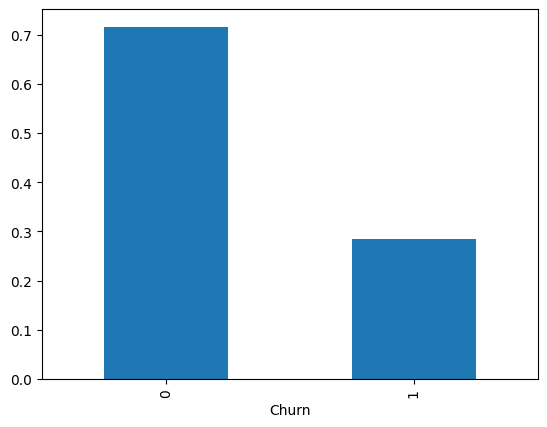

In [20]:
churn_df["Churn"].value_counts(normalize=True).plot.bar();

## Notes

* The target distribution is shown here to provide a quick visual of the class balance before comparing features with churn.

## Explore Features

### Explore Numerical Features

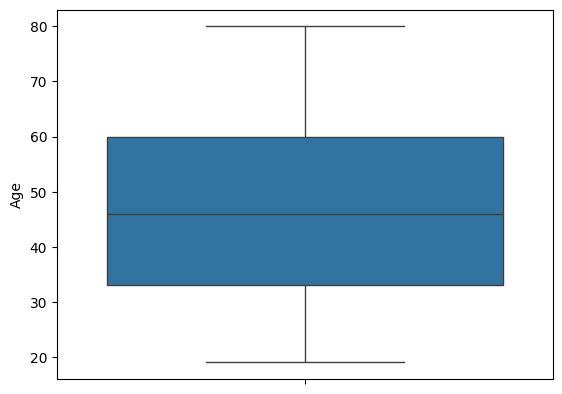

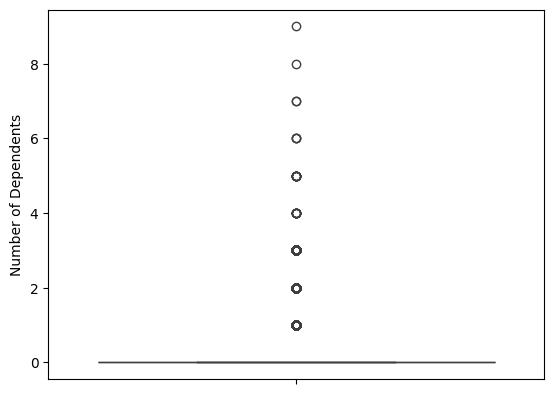

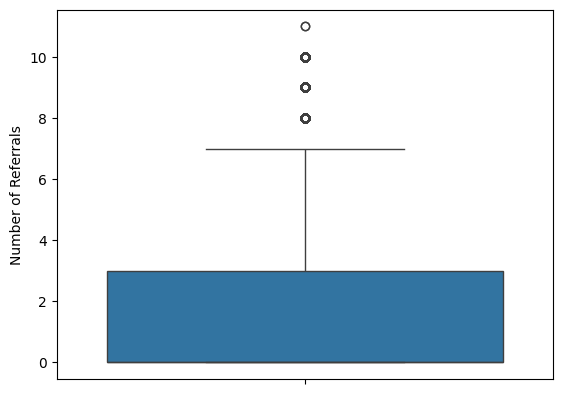

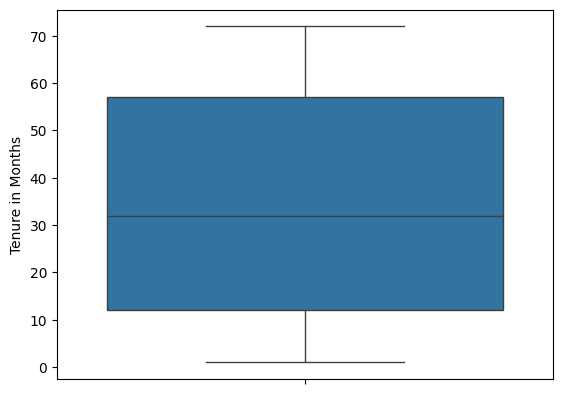

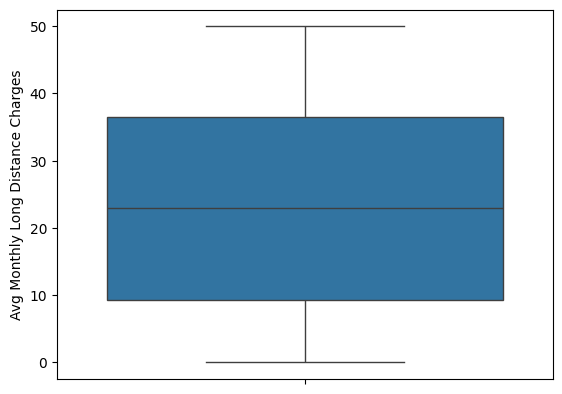

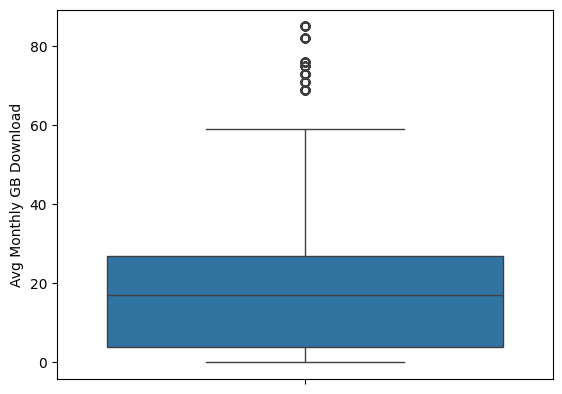

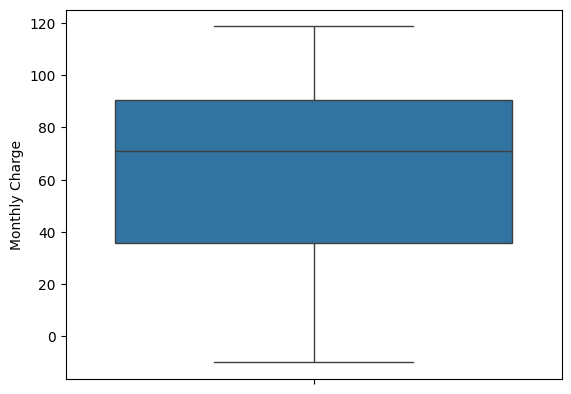

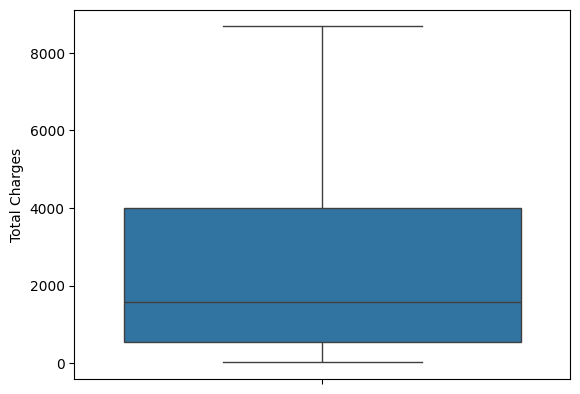

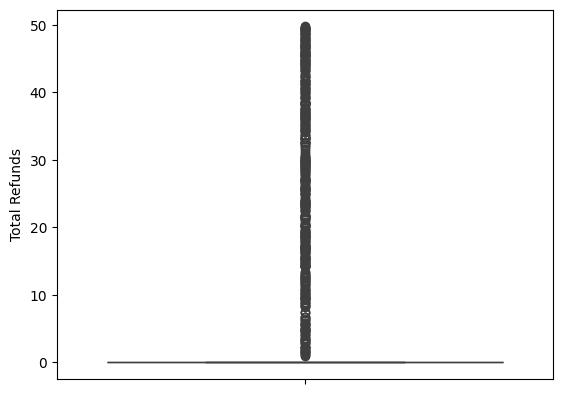

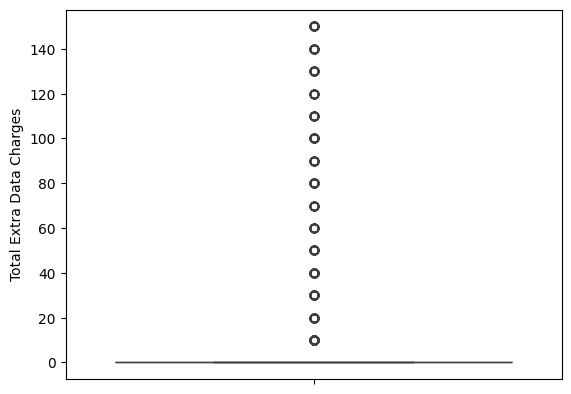

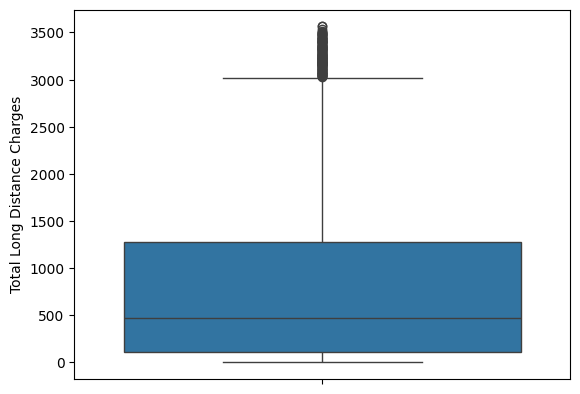

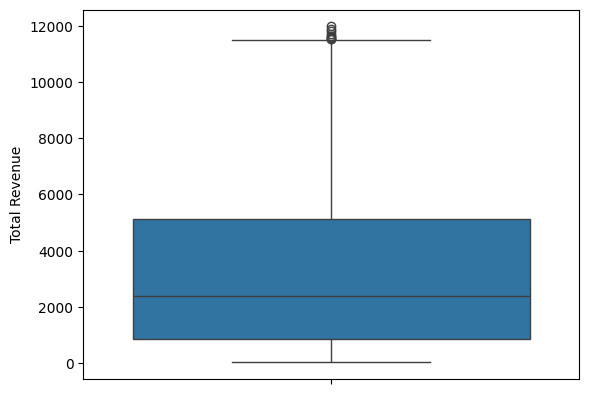

In [21]:
numerical_cols = [
    column for column in churn_df.select_dtypes("number").columns
    if column not in [
        'Zip Code',
        'Latitude',
        'Longitude',
        'Churn'
    ]
]

for column in numerical_cols:
    sns.boxplot(churn_df[column]).set(ylabel=column)
    plt.show()

### Notes

* Several numerical features have a lot of zero values or have skewed distributions, especially `Total Refunds` and `Total Extra Data Charges`.

* Some boxplots show extreme values, but these values are not automatically data errors and will not be removed based only on the boxplots.

* `Monthly Charge` contains negative values and will be investigated separately.

### Explore Categorical Features

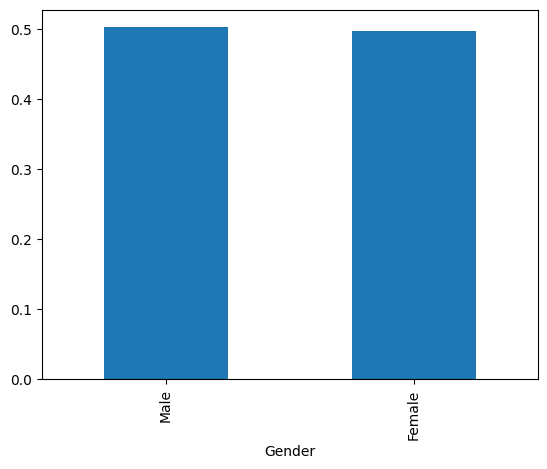

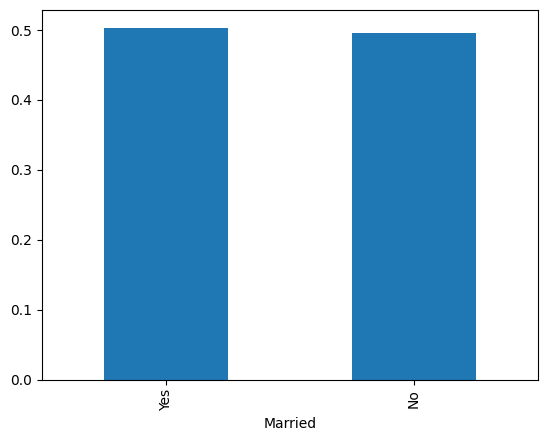

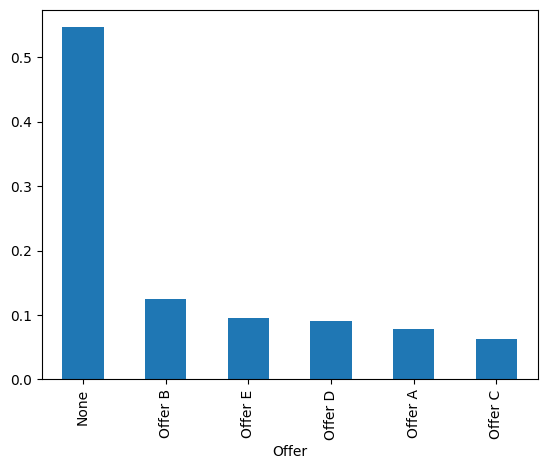

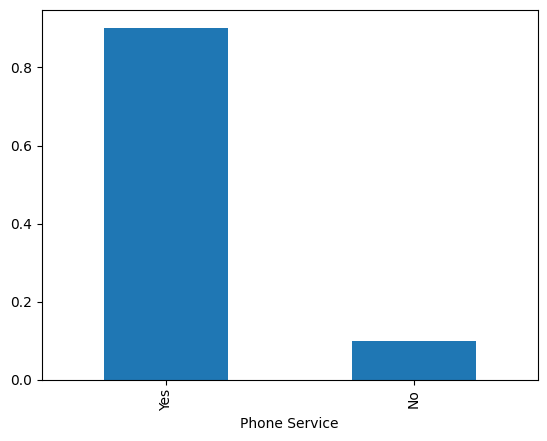

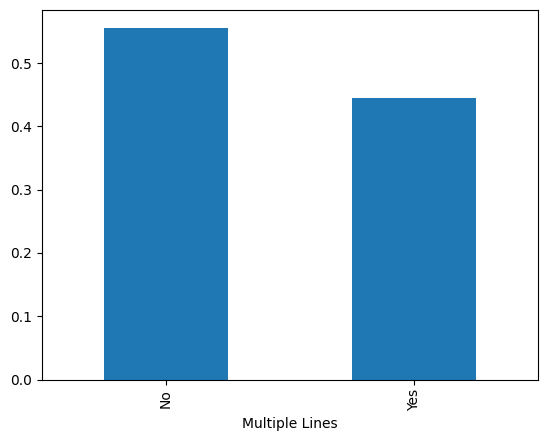

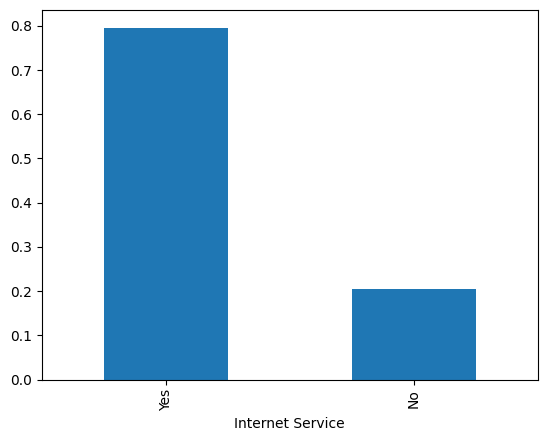

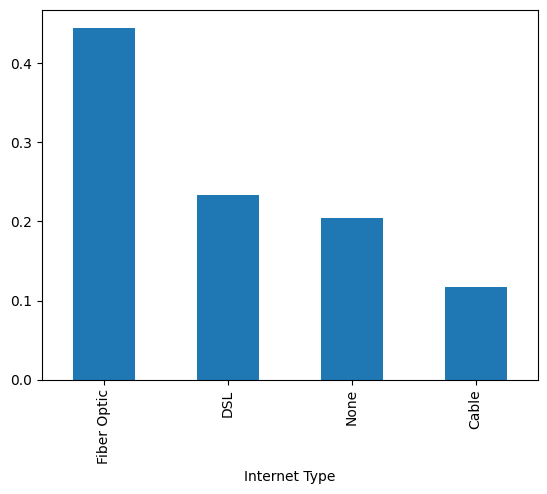

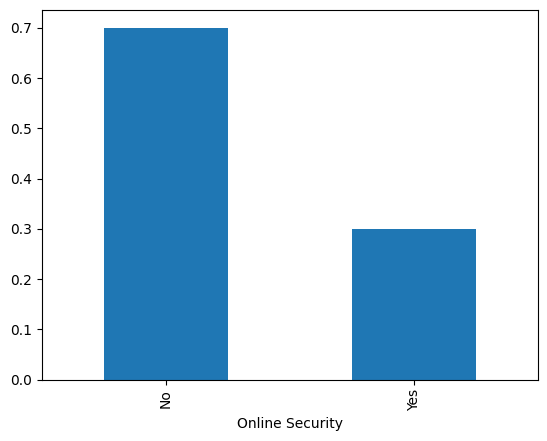

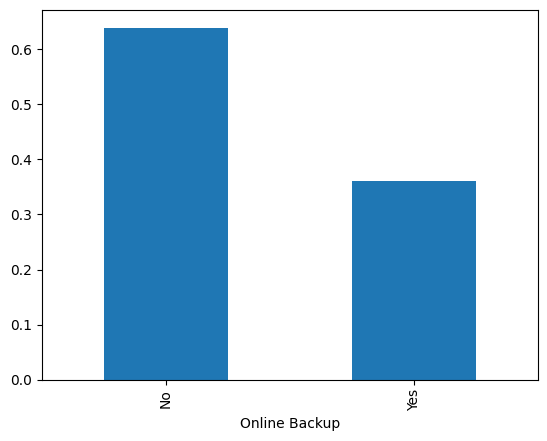

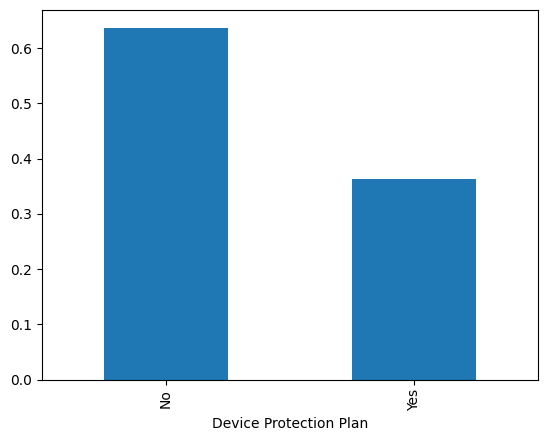

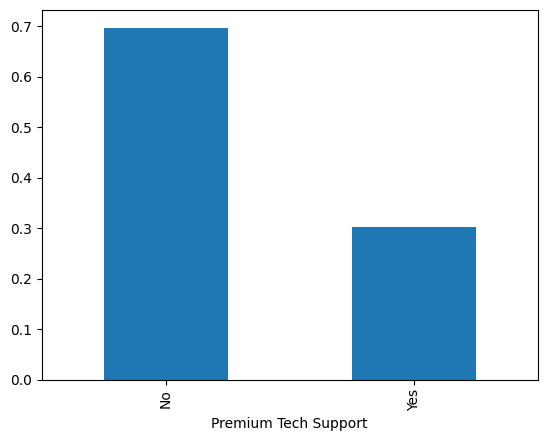

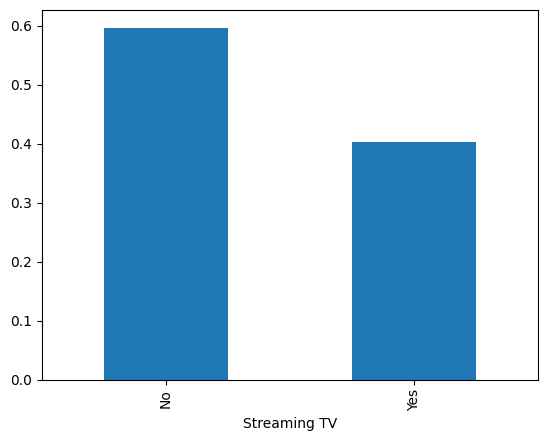

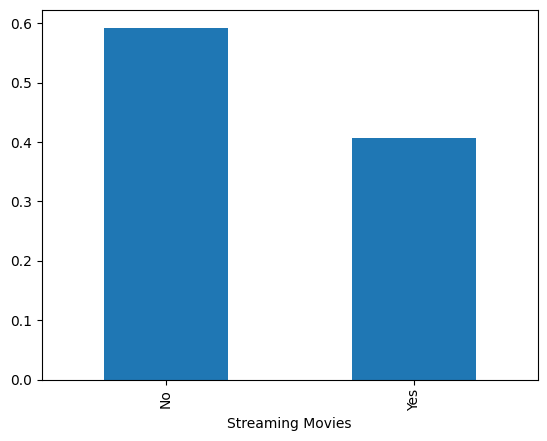

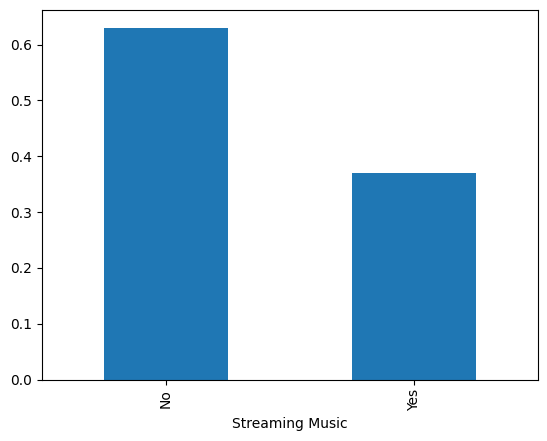

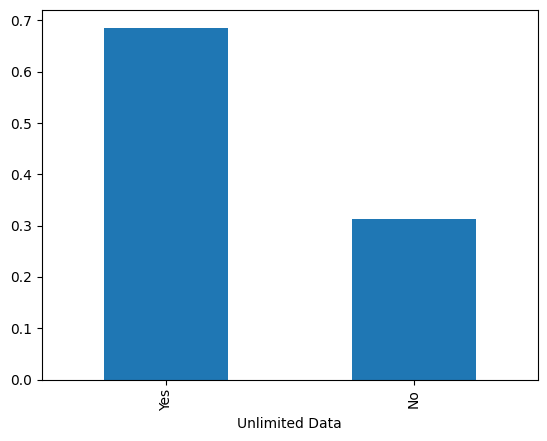

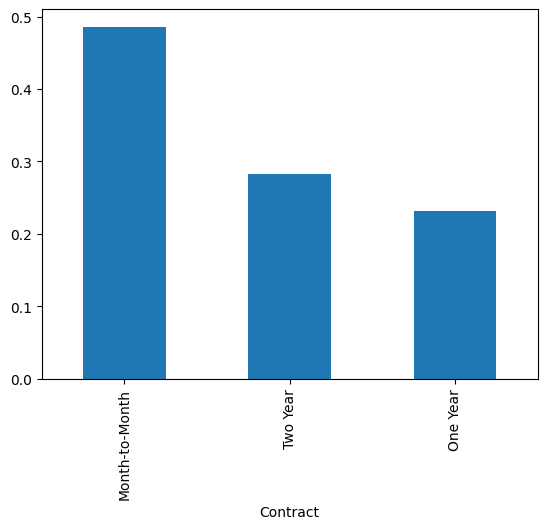

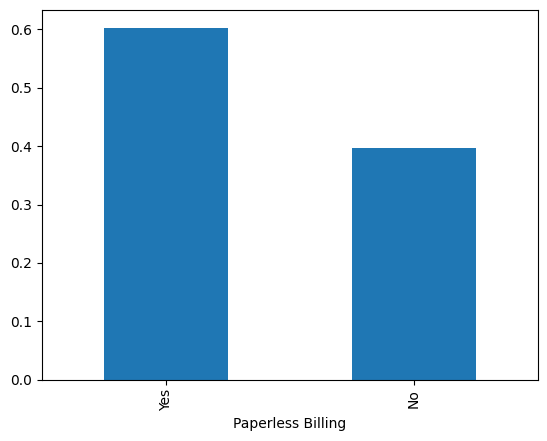

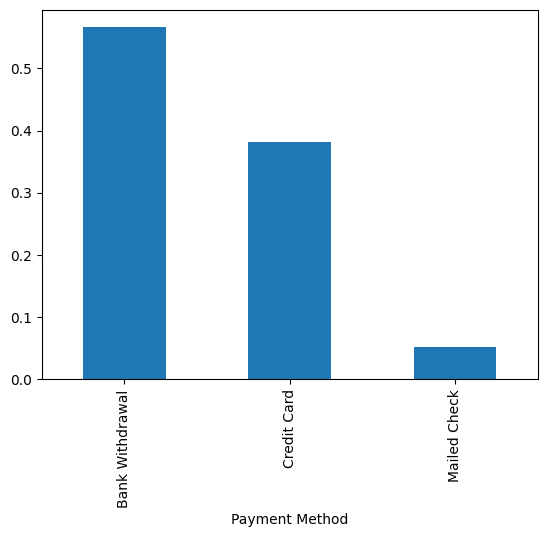

In [22]:
categorical_cols = [
    column for column in churn_df.select_dtypes("object").columns
    if column not in [
        'City',
        'Customer Status',
        'Churn Category',
        'Churn Reason'
    ]
]

for column in categorical_cols:
    churn_df[column].value_counts(normalize=True).plot.bar()
    plt.show()

### Notes

* Gender and marital status are fairly evenly distributed across customers.

* Most customers have phone and internet service, and fiber optic is the most common internet type.

* Month-to-month contracts are the most common contract type.

* Many customers do not have additional services such as `Online Security` or `Premium Tech Support`.

### Investigate Negative Monthly Charges

In [23]:
negative_monthly = churn_df[
    churn_df['Monthly Charge'] < 0
]

negative_monthly[
    ['Monthly Charge', 'Total Charges', 'Total Revenue']
].agg(['count', 'min', 'max'])

,Monthly Charge,Total Charges,Total Revenue
count,114.0,114.00,114.00
min,-10.0,19.40,22.54
max,-1.0,7942.15,10830.97


### Notes

* 114 customers have negative `Monthly Charge` values, ranging from -10 to -1.

* These customers still have positive `Total Charges` and `Total Revenue` values.

* The negative monthly charges are unusual, but there is not enough evidence to treat them as data errors, so they will be kept unchanged.

## Explore Reported Churn Reasons

### Churn Category

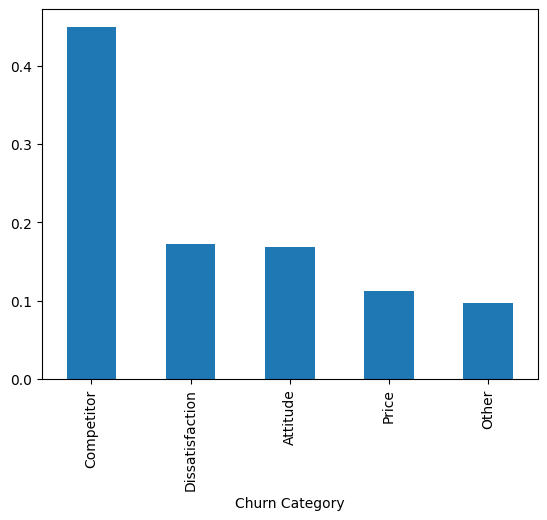

In [24]:
churn_df['Churn Category'].value_counts(normalize=True).plot.bar()
plt.show()

### Notes

* Competitor-related reasons are the most common churn category since they account for about 45% of reported churn.

* Dissatisfaction and attitude-related issues are the next most common categories, while price represents a smaller share of reported churn.

### Churn Reason

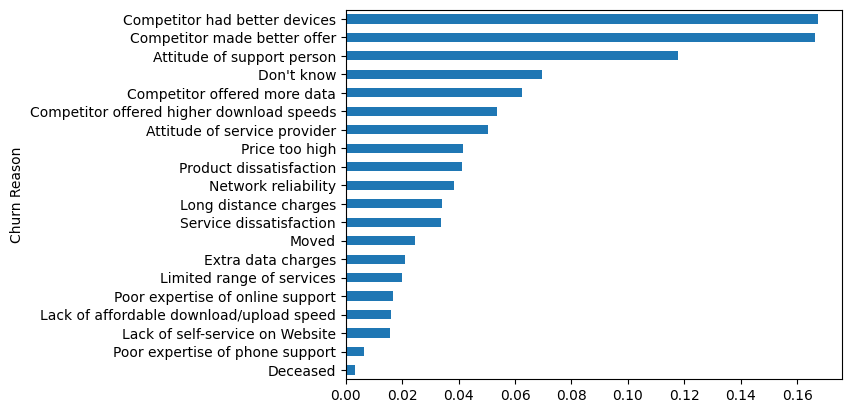

In [25]:
churn_df['Churn Reason'].value_counts(
    normalize=True
).sort_values().plot.barh()

plt.show()

### Notes

* The two most common reported churn reasons are that a competitor had better devices or made a better offer.

* Customer service also appears important, with `Attitude of support person` among the most common individual churn reasons.

* These results suggest that competition and customer service experience may be important areas for the company to focus on when developing retention strategies.

## Explore Feature Relationships with Churn

### Numerical Features

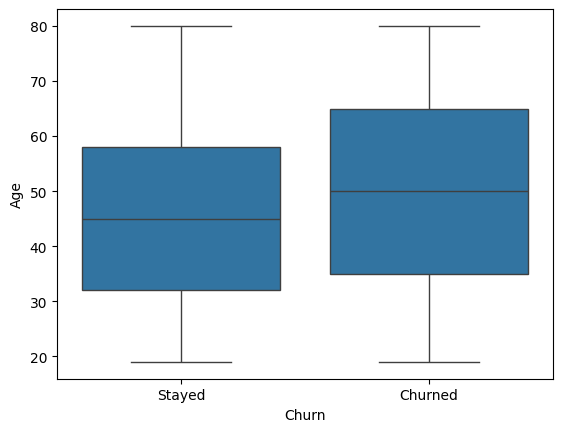

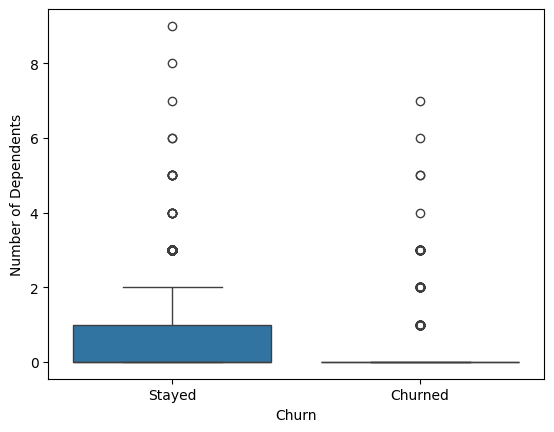

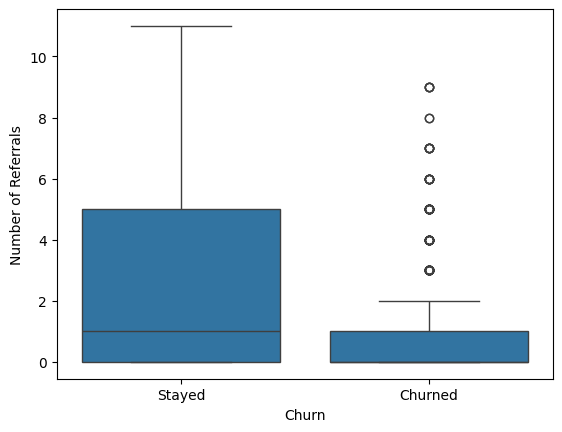

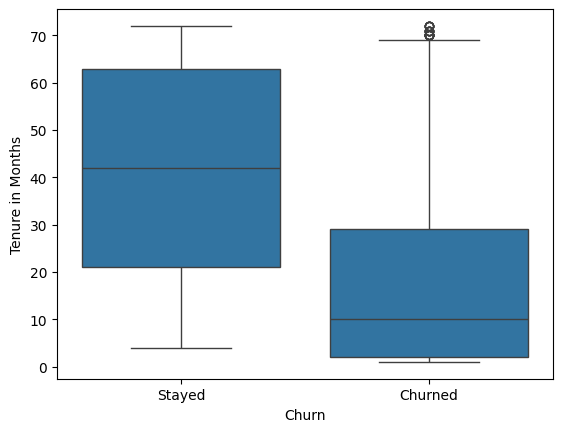

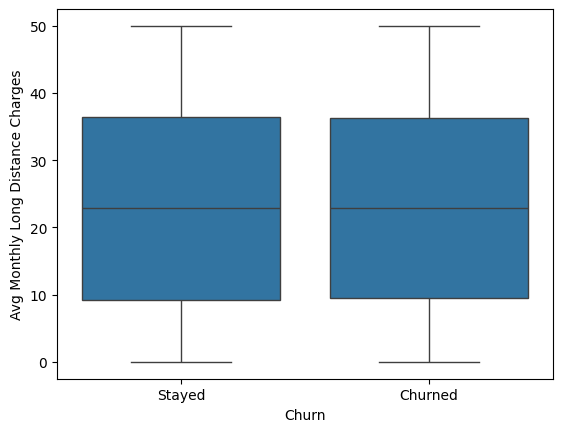

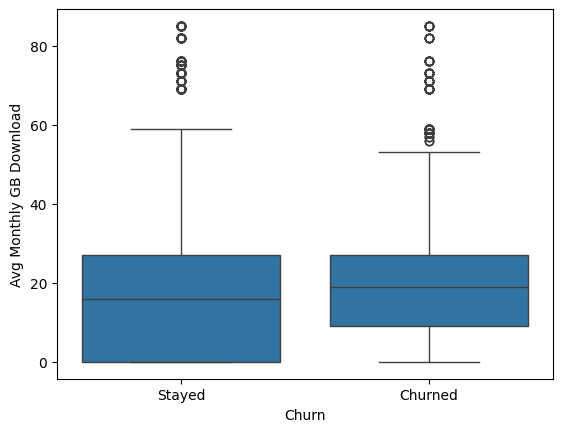

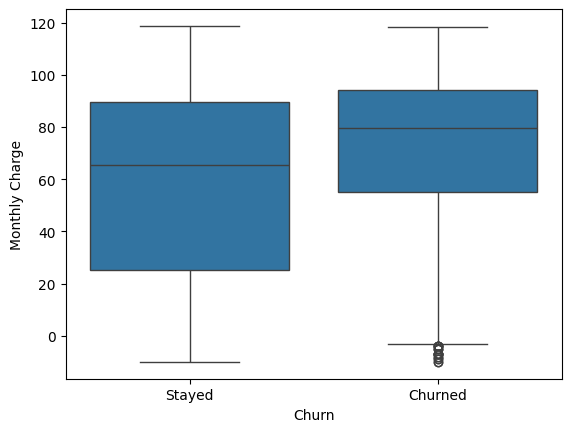

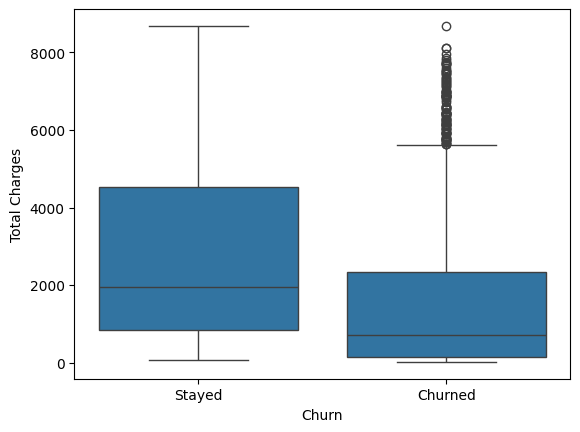

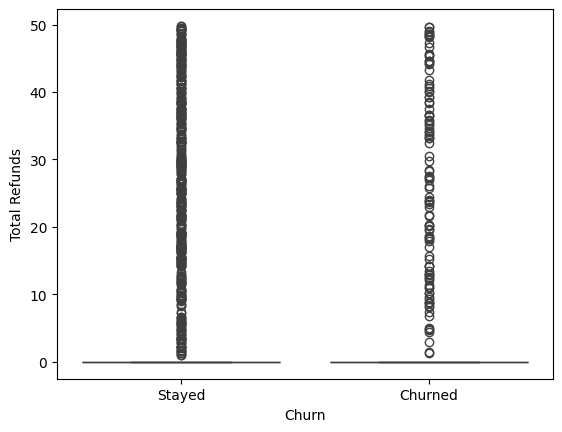

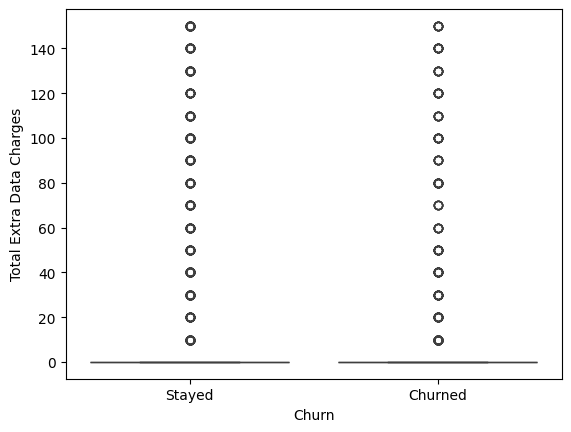

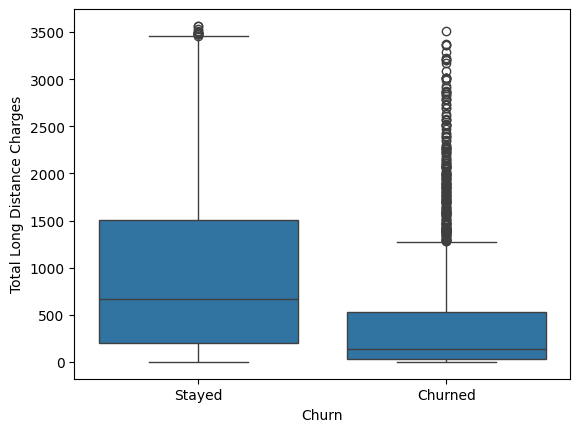

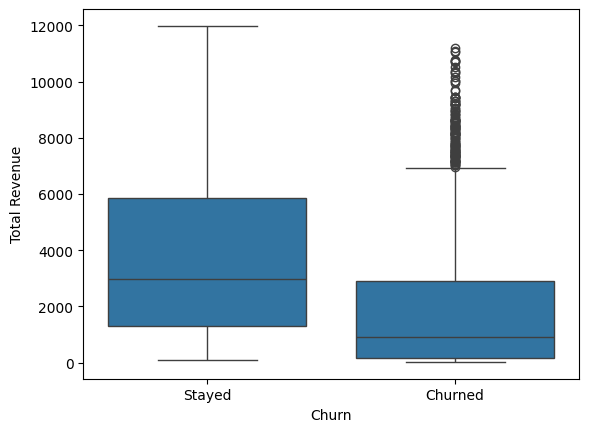

In [26]:
for column in numerical_cols:
    sns.boxplot(
        data=churn_df,
        x='Churn',
        y=column
    )

    plt.xticks([0, 1], ['Stayed', 'Churned'])
    plt.show()

### Notes

* Customers who churned tend to have much shorter tenure and fewer referrals than customers who stayed.

* Customers who churned generally have higher monthly charges and are slightly older than customers who stayed.

* Customers who stayed generally have higher `Total Charges`, `Total Long Distance Charges`, and `Total Revenue`, which could be because they have been customers for longer.

* `Avg Monthly Long Distance Charges`, `Total Refunds`, and `Total Extra Data Charges` look fairly similar between customers who stayed and customers who churned.

### Categorical Features

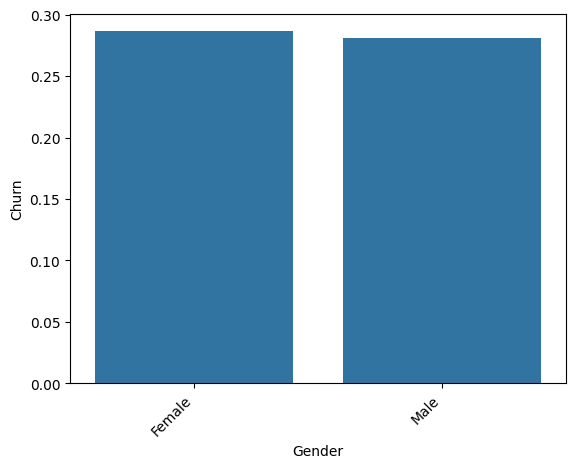

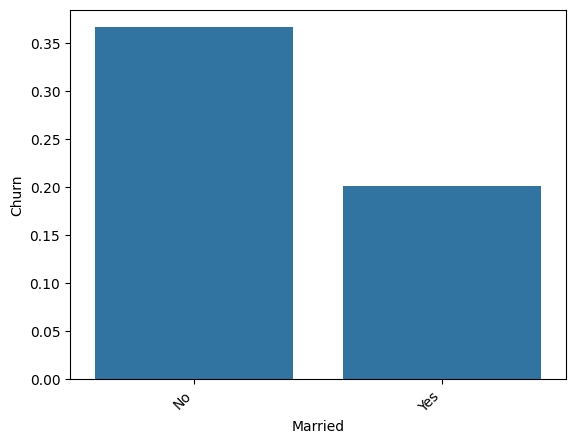

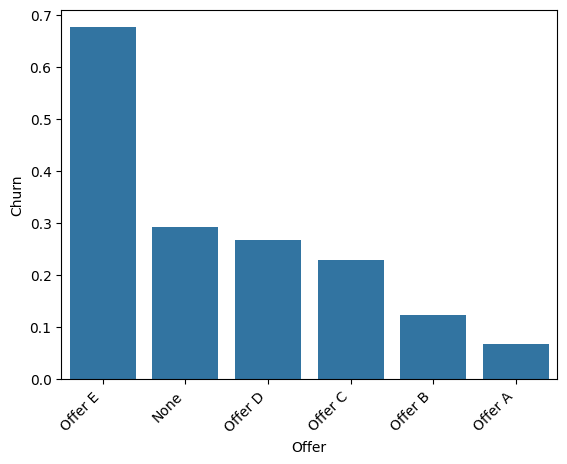

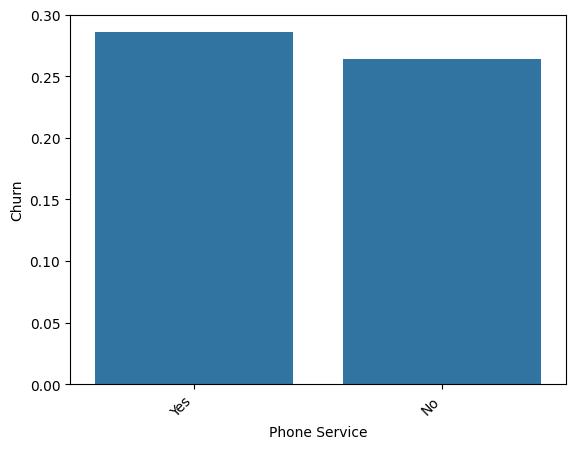

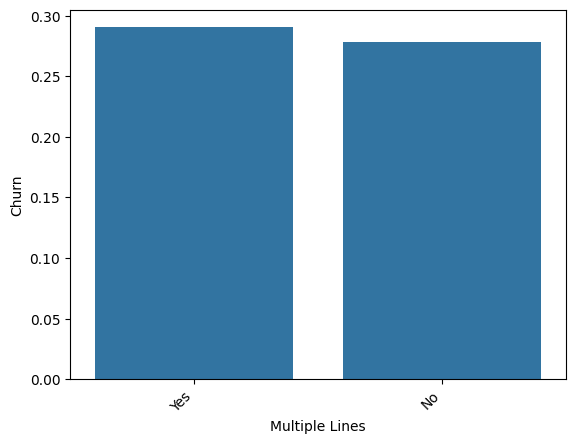

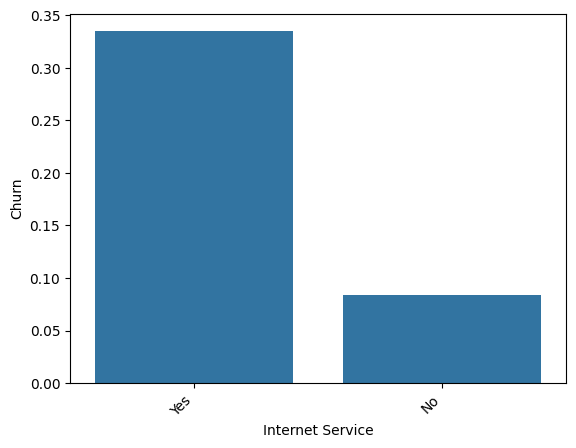

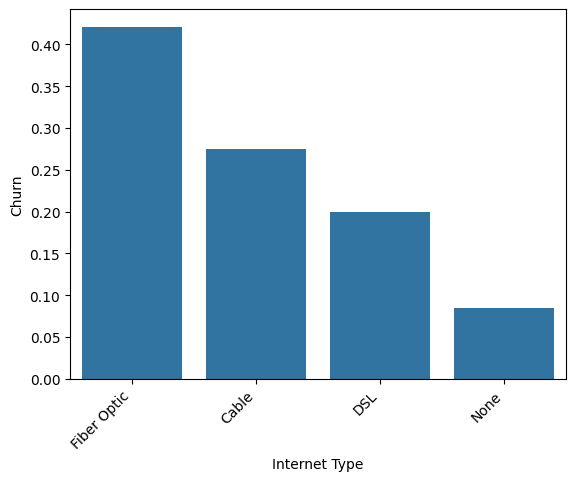

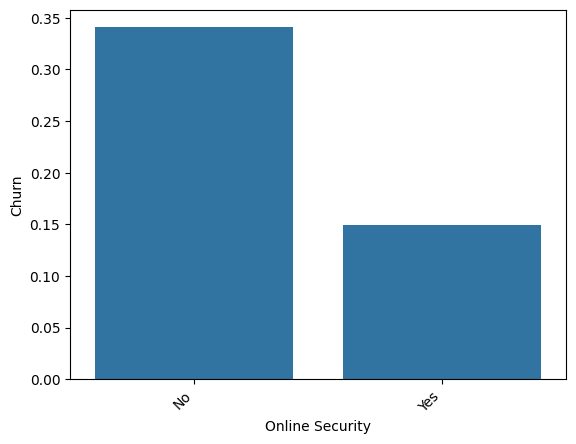

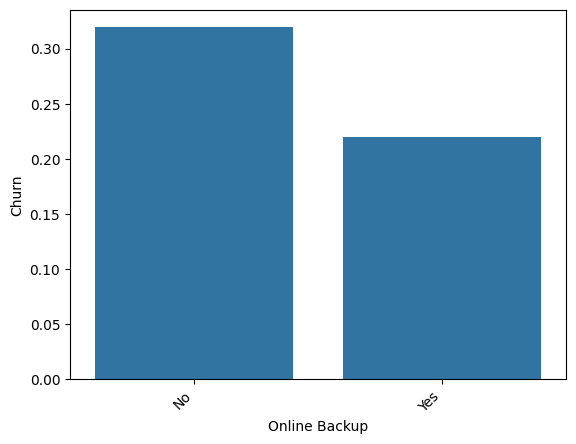

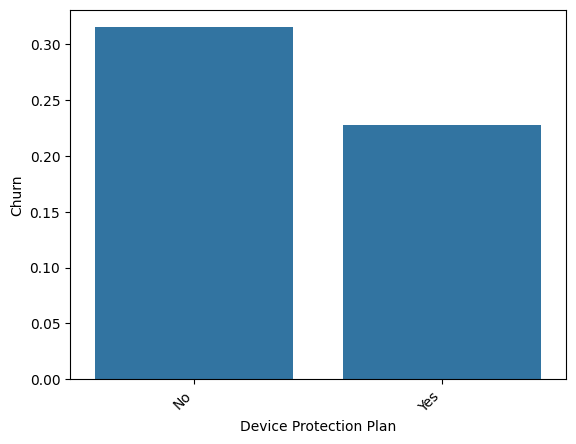

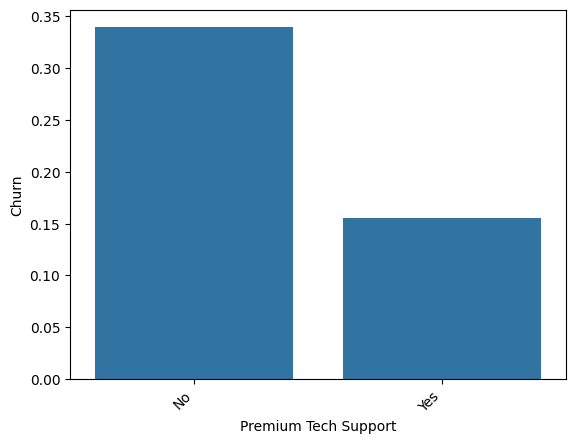

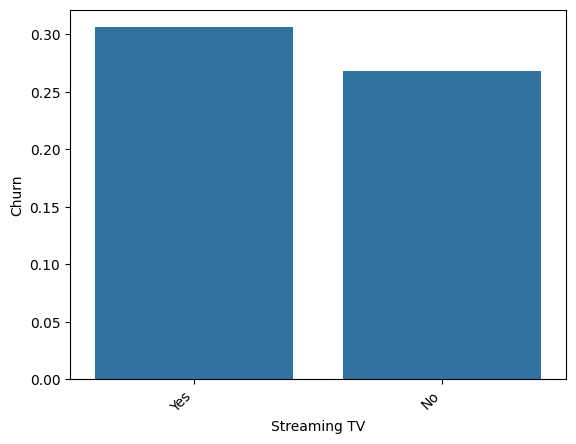

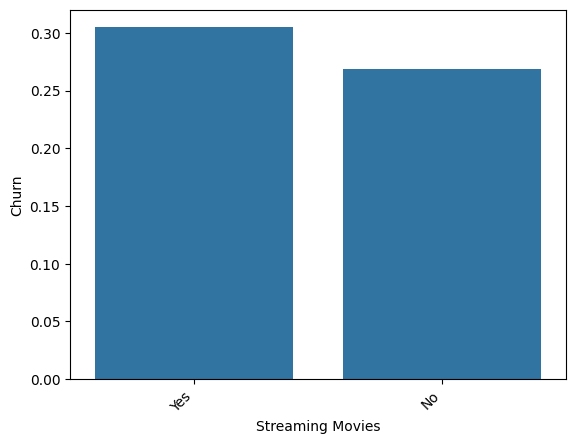

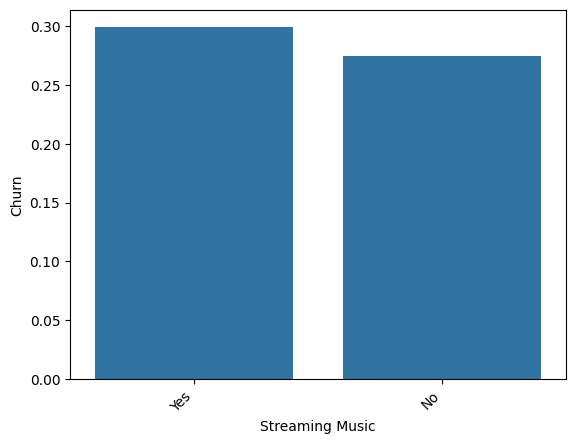

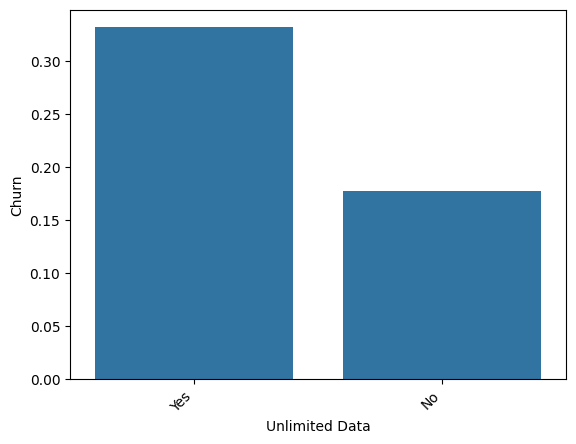

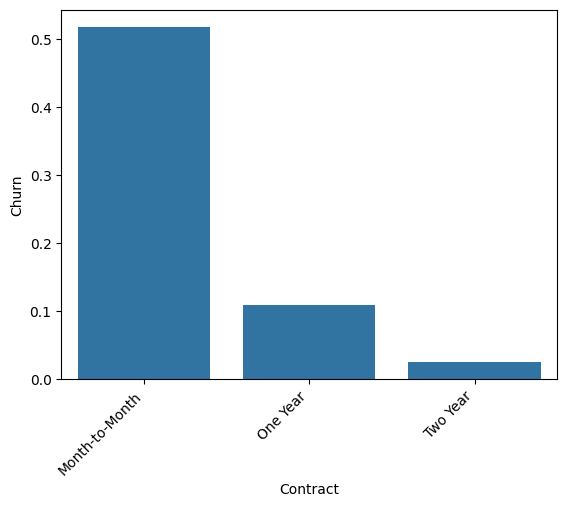

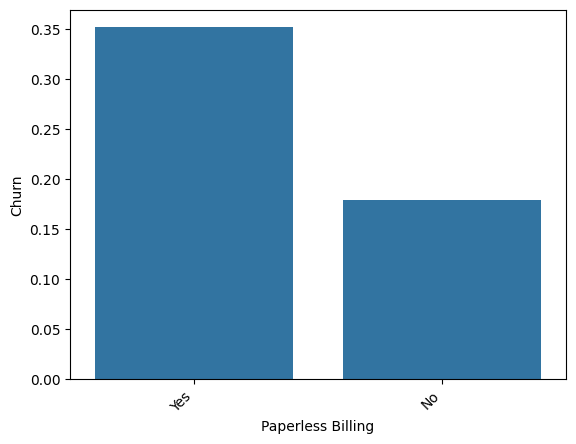

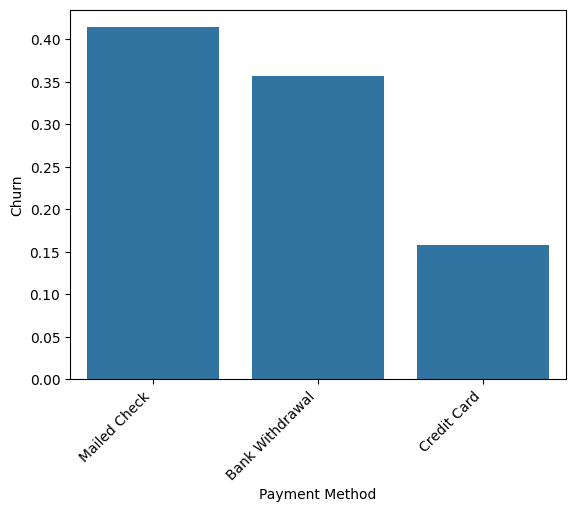

In [27]:
for column in categorical_cols:
    churn_rates = (
        churn_df
        .groupby(column, as_index=False)
        .agg({'Churn': 'mean'})
        .sort_values(by='Churn', ascending=False)
    )

    sns.barplot(
        data=churn_rates,
        x=column,
        y='Churn'
    )

    plt.xticks(rotation=45, ha='right')
    plt.show()

### Notes

* Month-to-month customers have a much higher churn rate than customers with one-year or two-year contracts.

* Customers with fiber optic internet have a higher churn rate than customers with cable, DSL, or no internet service.

* Customers without `Online Security` or `Premium Tech Support` have higher churn rates than customers who have these services.

* Customers who are not married, use paperless billing, or pay by mailed check or bank withdrawal also have higher churn rates.

* Gender, phone service, multiple lines, and streaming services show smaller differences in churn rates.

## Explore Numerical Correlations

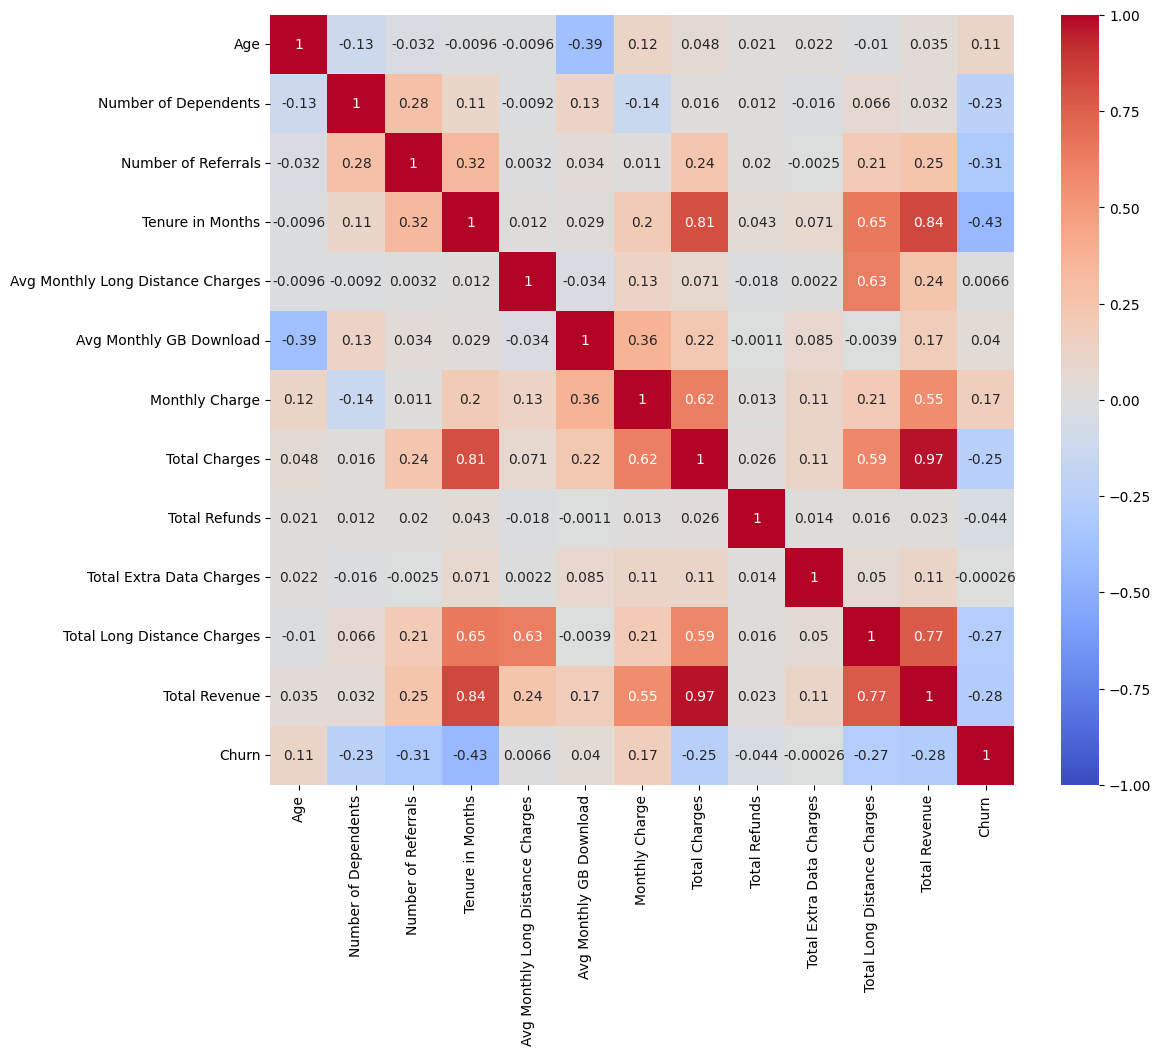

In [28]:
corr_cols = numerical_cols + ['Churn']

plt.figure(figsize=(12, 10))

sns.heatmap(
    churn_df[corr_cols].corr(),
    vmin=-1,
    vmax=1,
    cmap='coolwarm',
    annot=True
)

plt.show()

### Notes

* `Total Charges` and `Total Revenue` have a very strong positive correlation.

* `Tenure in Months` is strongly related to `Total Charges` and `Total Revenue`, which makes sense because customers who stay longer generally spend more over time.

* `Tenure in Months` has the strongest relationship with churn, and customers who stay longer are less likely to churn.

* `Number of Referrals`, `Total Revenue`, `Total Long Distance Charges`, and `Total Charges` also have negative relationships with churn, while `Monthly Charge` has a smaller positive relationship.

## Explore Important Feature-Feature Relationships

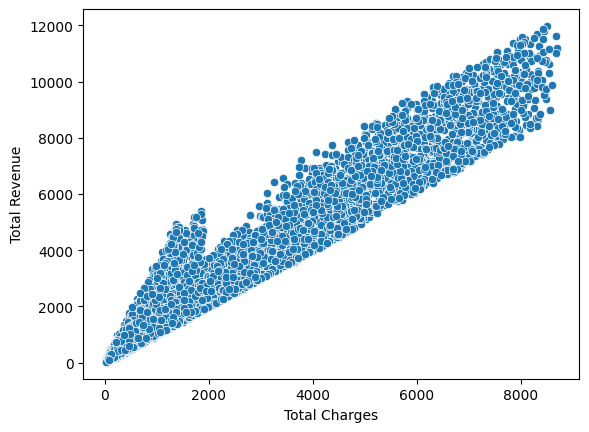

In [29]:
sns.scatterplot(
    data=churn_df,
    x='Total Charges',
    y='Total Revenue'
)

plt.show()

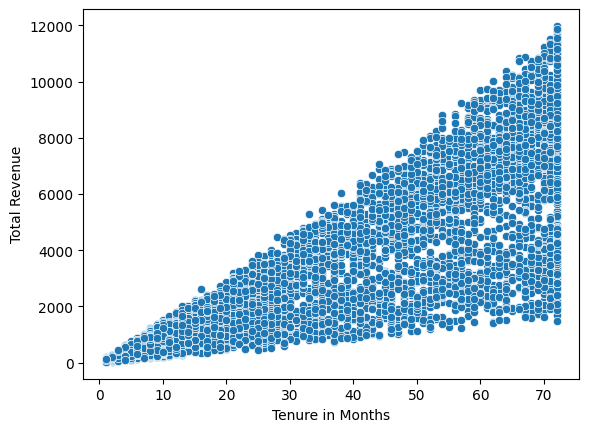

In [30]:
sns.scatterplot(
    data=churn_df,
    x='Tenure in Months',
    y='Total Revenue'
)

plt.show()

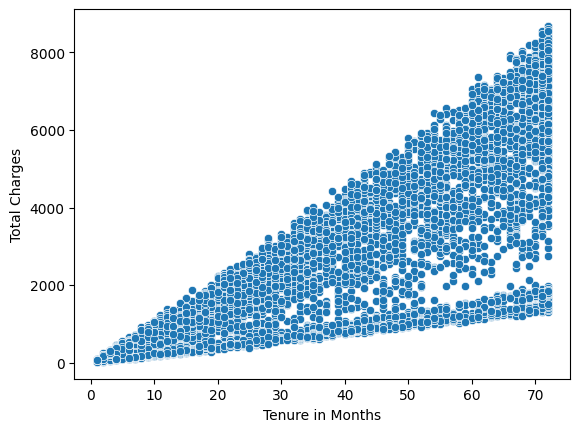

In [31]:
sns.scatterplot(
    data=churn_df,
    x='Tenure in Months',
    y='Total Charges'
)

plt.show()

### Notes

* `Total Charges` and `Total Revenue` have a very strong positive relationship.

* `Total Charges` and `Total Revenue` generally increase as customer tenure increases.

* Customers with similar tenure can still have very different total charges and revenue.

# 3. Feature Selection

## Select Features for Modeling

In [32]:
columns_to_remove = [
    'Customer Status',
    'Churn Category',
    'Churn Reason',
    'City',
    'Zip Code',
    'Latitude',
    'Longitude'
]

model_df = churn_df.drop(columns=columns_to_remove)

### Notes

* `Customer Status`, `Churn Category`, and `Churn Reason` were removed because they already tell us whether a customer churned or why they churned, which would cause data leakage.

* `City`, `Zip Code`, `Latitude`, and `Longitude` were removed because they show where customers are located rather than how they use their services or manage their accounts.

# 4. Prepare the Data for Modeling

## Encode Categorical Features

In [33]:
churn_modeling_df = pd.get_dummies(
    model_df,
    drop_first=True,
    dtype=int
)

churn_modeling_df.head()

,Age,Number of Dependents,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,...,Premium Tech Support_Yes,Streaming TV_Yes,Streaming Movies_Yes,Streaming Music_Yes,Unlimited Data_Yes,Contract_One Year,Contract_Two Year,Paperless Billing_Yes,Payment Method_Credit Card,Payment Method_Mailed Check
0,37,0,2,9,42.39,16.0,65.6,593.30,0.00,0,...,1,1,0,0,1,1,0,1,1,0
1,46,0,0,9,10.69,10.0,-4.0,542.40,38.33,10,...,0,0,1,1,0,0,0,0,1,0
2,50,0,0,4,33.65,30.0,73.9,280.85,0.00,0,...,0,0,0,0,1,0,0,1,0,0
3,78,0,1,13,27.82,4.0,98.0,1237.85,0.00,0,...,0,1,1,0,1,0,0,1,0,0
4,75,0,3,3,7.38,11.0,83.9,267.40,0.00,0,...,1,1,0,0,1,0,0,1,1,0


### Notes

* Categorical features were converted into dummy variables so they can be used by the classification models.

## Split Features and Target

In [34]:
X = churn_modeling_df.drop(columns='Churn')
y = churn_modeling_df['Churn']

### Notes

* `X` contains the features that will be used to predict customer churn.

* `y` contains the existing `Churn` target that the models will try to predict.

## Train-Test Split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2026,
    stratify=y
)

print(f"Training Set Rows: {X_train.shape[0]}")
print(f"Test Set Rows: {X_test.shape[0]}")

Training Set Rows: 5271
Test Set Rows: 1318


In [36]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5271 entries, 5442 to 3524
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                5271 non-null   int64  
 1   Number of Dependents               5271 non-null   int64  
 2   Number of Referrals                5271 non-null   int64  
 3   Tenure in Months                   5271 non-null   int64  
 4   Avg Monthly Long Distance Charges  5271 non-null   float64
 5   Avg Monthly GB Download            5271 non-null   float64
 6   Monthly Charge                     5271 non-null   float64
 7   Total Charges                      5271 non-null   float64
 8   Total Refunds                      5271 non-null   float64
 9   Total Extra Data Charges           5271 non-null   int64  
 10  Total Long Distance Charges        5271 non-null   float64
 11  Total Revenue                      5271 non-null   float64

### Notes

* The data was split into 80% training data and 20% test data.

* `stratify=y` was used to keep the proportion of stayed and churned customers similar in both datasets.

## Standardize Features

In [37]:
std = StandardScaler()

X_train_std = std.fit_transform(X_train)
X_test_std = std.transform(X_test)

### Notes

* The scaler was fit on the training data and then used to standardize both the training and test data.

* This prevents information from the test data from being used when preparing the training data.

# 5. Build and Evaluate Models

## K-Nearest Neighbors

In [38]:
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_std, y_train)

KNeighborsClassifier()

In [39]:
knn_train_predictions = knn.predict(X_train_std)
knn_test_predictions = knn.predict(X_test_std)

In [40]:
print(f"Train Accuracy: {accuracy_score(y_train, knn_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, knn_test_predictions)}")

Train Accuracy: 0.866439005881237
Test Accuracy: 0.8004552352048558


In [41]:
print(confusion_matrix(y_train, knn_train_predictions))
print(confusion_matrix(y_test, knn_test_predictions))

[[3395  381]
 [ 323 1172]]
[[798 146]
 [117 257]]


### Notes

* The KNN model achieved about 86.6% accuracy on the training data and 80.0% accuracy on the test data.

* The higher training accuracy suggests that the model may be fitting the training data somewhat better than the test data.

* On the test data, the model correctly identified 257 customers who churned but missed 117 customers who actually churned.

### Tune the KNN Model

In [42]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

In [43]:
parameters = {
    'knn__n_neighbors': range(1, 50)
}

gridsearch = GridSearchCV(
    knn_pipeline,
    parameters,
    cv=5,
    scoring='f1'
)

gridsearch.fit(X_train, y_train);

In [44]:
best_k = gridsearch.best_params_['knn__n_neighbors']

best_k

35

In [45]:
tuned_knn = gridsearch.best_estimator_

In [46]:
tuned_knn_train_predictions = tuned_knn.predict(X_train)
tuned_knn_test_predictions = tuned_knn.predict(X_test)

In [47]:
print(f"Train Accuracy: {accuracy_score(y_train, tuned_knn_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, tuned_knn_test_predictions)}")

Train Accuracy: 0.8283058243217606
Test Accuracy: 0.8103186646433991


In [48]:
print(confusion_matrix(y_train, tuned_knn_train_predictions))
print(confusion_matrix(y_test, tuned_knn_test_predictions))

[[3275  501]
 [ 404 1091]]
[[803 141]
 [109 265]]


### Notes

* GridSearchCV tested different values of `k` using 5-fold cross-validation and selected `k = 35` based on F1-score.

* The tuned KNN model achieved about 82.8% accuracy on the training data and 81.0% accuracy on the test data.

* The smaller difference between the training and test accuracy suggests that the tuned model is less overfit than the original KNN model.

* The tuned model correctly identified 265 customers who churned and missed 109, improving slightly over the original KNN model.

## Logistic Regression

In [49]:
logreg = LogisticRegression(max_iter=1000)

logreg.fit(X_train_std, y_train)

LogisticRegression(max_iter=1000)

In [50]:
logreg_train_predictions = logreg.predict(X_train_std)
logreg_test_predictions = logreg.predict(X_test_std)

In [51]:
print(f"Train Accuracy: {accuracy_score(y_train, logreg_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, logreg_test_predictions)}")

Train Accuracy: 0.8586605957123885
Test Accuracy: 0.8558421851289834


In [52]:
print(confusion_matrix(y_train, logreg_train_predictions))
print(confusion_matrix(y_test, logreg_test_predictions))

[[3415  361]
 [ 384 1111]]
[[853  91]
 [ 99 275]]


### Notes

* The Logistic Regression model was about 85.9% accurate on the training data and 85.6% accurate on the test data.

* The training and test accuracy are very similar, suggesting the model also works well on new data and shows no clear signs of overfitting.

* The model correctly predicted 275 customers who churned, but it missed 99 customers who also churned.

### Tune the Logistic Regression Model

In [53]:
logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        solver='saga',
        max_iter=5000
    ))
])

In [54]:
parameters = {
    'logreg__C': np.linspace(0.1, 2, 20),
    'logreg__penalty': ['l1', 'l2']
}

In [55]:
logreg_gridsearch = GridSearchCV(
    logreg_pipeline,
    parameters,
    cv=5,
    scoring='f1'
)

logreg_gridsearch.fit(X_train, y_train);

In [56]:
logreg_gridsearch.best_params_

{'logreg__C': np.float64(1.9), 'logreg__penalty': 'l2'}

In [57]:
tuned_logreg = logreg_gridsearch.best_estimator_

In [58]:
tuned_logreg_train_predictions = tuned_logreg.predict(X_train)
tuned_logreg_test_predictions = tuned_logreg.predict(X_test)

In [59]:
print(f"Train Accuracy: {accuracy_score(y_train, tuned_logreg_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, tuned_logreg_test_predictions)}")

Train Accuracy: 0.85885031303358
Test Accuracy: 0.855083459787557


In [60]:
print(confusion_matrix(y_train, tuned_logreg_train_predictions))
print(confusion_matrix(y_test, tuned_logreg_test_predictions))

[[3413  363]
 [ 381 1114]]
[[853  91]
 [100 274]]


### Notes

* GridSearchCV selected `C = 1.9` with L2 regularization as the best settings based on 5-fold cross-validation.

* The tuned model was about 85.9% accurate on the training data and 85.5% accurate on the test data.

* The tuned model performed very similarly to the original Logistic Regression model and did not improve the test results.

* The tuned model correctly predicted 274 customers who churned but missed 100 customers who churned.

## Decision Tree

### Baseline Decision Tree

In [61]:
dt = DecisionTreeClassifier(
    max_depth=3,
    random_state=2026
)

dt.fit(X_train, y_train);

In [62]:
dt_train_predictions = dt.predict(X_train)
dt_test_predictions = dt.predict(X_test)

In [63]:
print(f"Train Accuracy: {accuracy_score(y_train, dt_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, dt_test_predictions)}")

Train Accuracy: 0.807057484348321
Test Accuracy: 0.8065250379362671


In [64]:
print(confusion_matrix(y_train, dt_train_predictions))
print(confusion_matrix(y_test, dt_test_predictions))

[[3776    0]
 [1017  478]]
[[944   0]
 [255 119]]


### Notes

* The Decision Tree model was about 80.7% accurate on both the training and test data.

* Similar training and test accuracy suggests that the model is not showing clear signs of overfitting.

* The model correctly predicted 119 customers who churned but missed 255 customers who churned.

* The model did a very good job at predicting customers who stayed, but had a harder time identifying customers who churned.

### Decision Tree Visualization

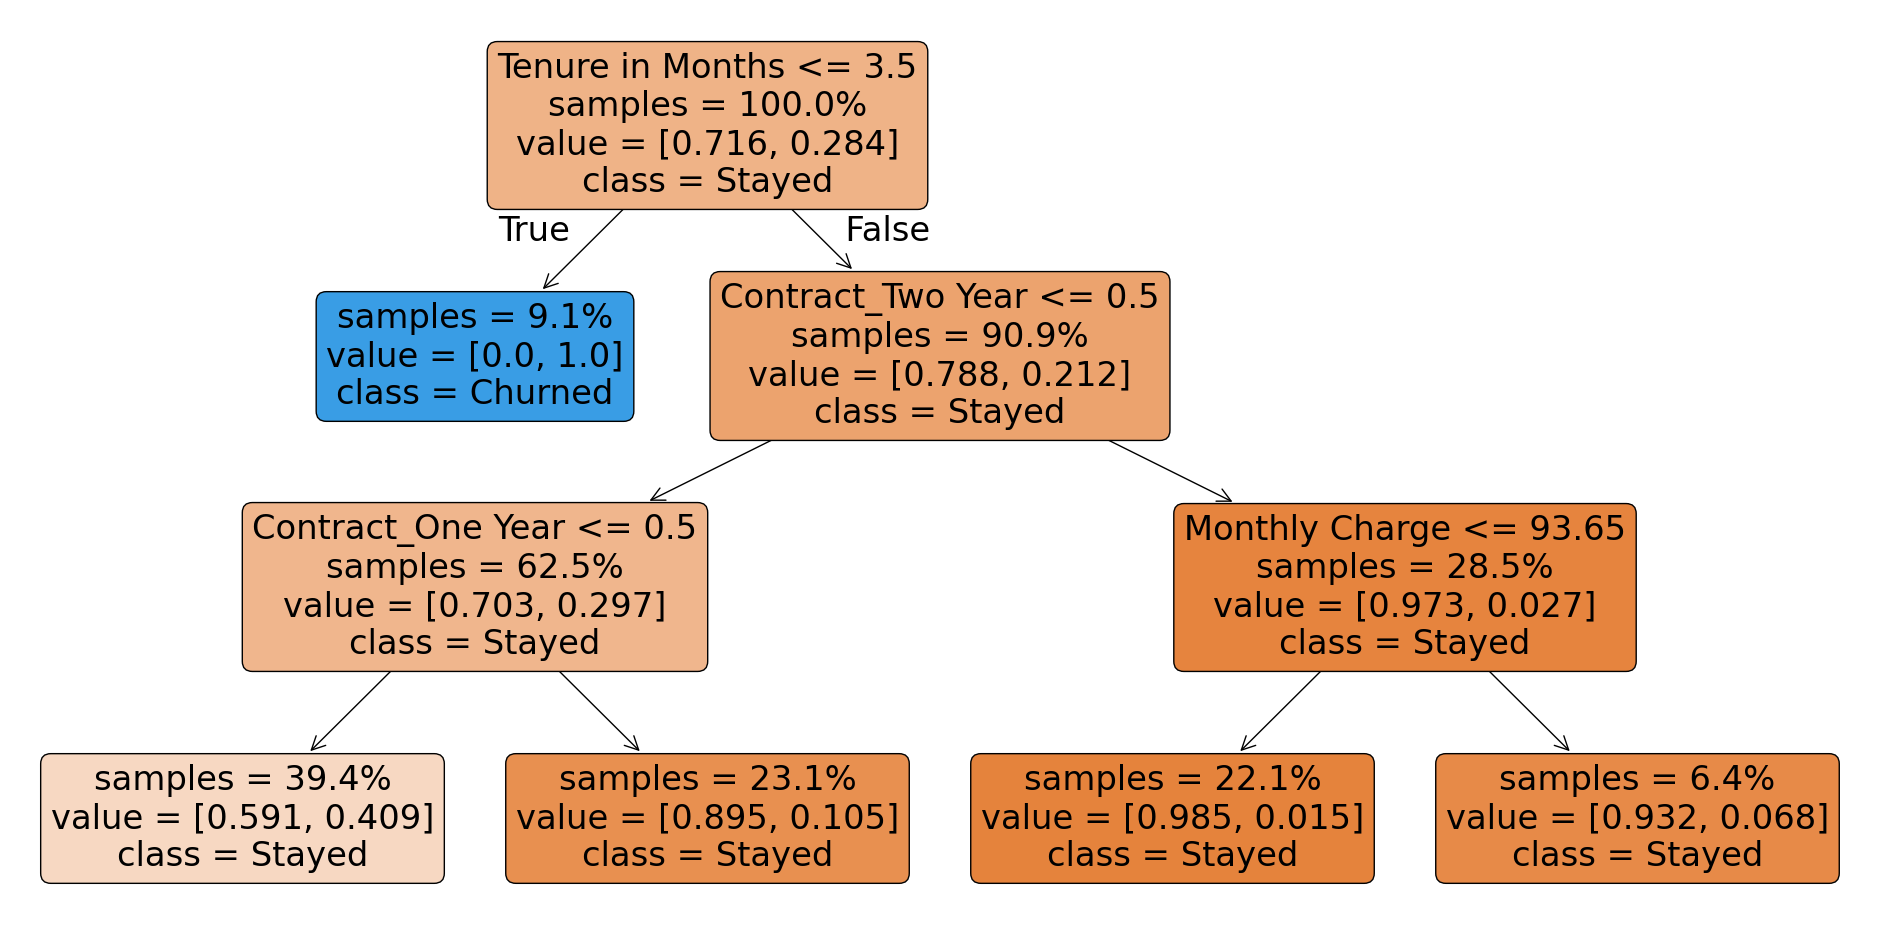

In [65]:
plt.figure(figsize=(24, 12))

plot_tree(
    dt,
    feature_names=X_train.columns,
    class_names=['Stayed', 'Churned'],
    impurity=False,
    proportion=True,
    filled=True,
    rounded=True
)

plt.show()

### Notes

* `Tenure in Months` was the first feature the Decision Tree used to split customers.

* In the training data, customers with 3 months or less of tenure were placed into the churned group.

* For customers with more than 3 months of tenure, the tree found that contract type helped separate customers into groups with different churn rates.

* Customers with month-to-month contracts had a higher rate of churn than customers with one-year or two-year contracts.

### Feature Importance

In [66]:
importance_df = (
    pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': dt.feature_importances_
    })
    .sort_values(
        by='Importance',
        ascending=False
    )
)

importance_df.head(10)

,Feature,Importance
3,Tenure in Months,0.648245
34,Contract_Two Year,0.180562
33,Contract_One Year,0.169388
6,Monthly Charge,0.001806
1,Number of Dependents,0.000000
0,Age,0.000000
5,Avg Monthly GB Download,0.000000
4,Avg Monthly Long Distance Charges,0.000000
2,Number of Referrals,0.000000
7,Total Charges,0.000000


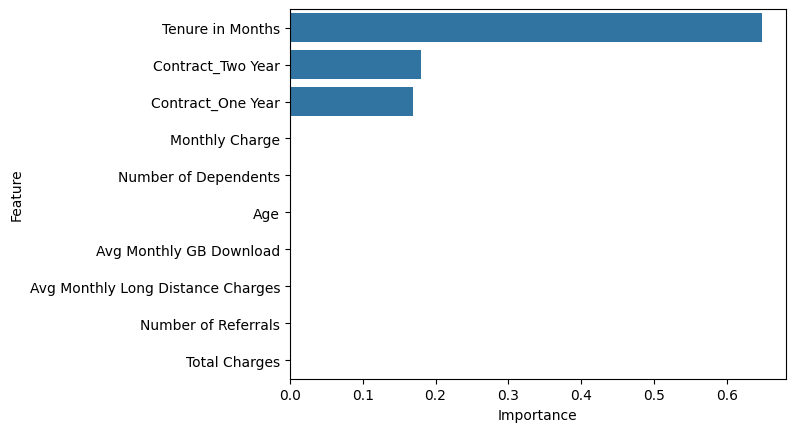

In [67]:
sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.show()

### Notes

* `Tenure in Months` was the most important feature used by this Decision Tree.

* One-year and two-year contract types were also important for the model's predictions.

* Monthly Charge had very little importance compared to tenure and contract type.

* Several features were not needed by this simple three-level tree, but that does not mean they are useless overall.

### Tune the Decision Tree Model

In [68]:
parameters = {
    'max_depth': [2, 5, 10, 20],
    'min_samples_leaf': [2, 5, 10, 20],
    'criterion': ['gini', 'entropy', 'log_loss']
}

In [69]:
dt_gridsearch = GridSearchCV(
    DecisionTreeClassifier(random_state=2026),
    parameters,
    cv=5,
    scoring='f1'
)

dt_gridsearch.fit(X_train, y_train);

In [70]:
dt_gridsearch.best_params_

{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 20}

In [71]:
tuned_dt = dt_gridsearch.best_estimator_

In [72]:
tuned_dt_train_predictions = tuned_dt.predict(X_train)
tuned_dt_test_predictions = tuned_dt.predict(X_test)

In [73]:
print(f"Train Accuracy: {accuracy_score(y_train, tuned_dt_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, tuned_dt_test_predictions)}")

Train Accuracy: 0.8814266742553595
Test Accuracy: 0.8672230652503794


In [74]:
print(confusion_matrix(y_train, tuned_dt_train_predictions))
print(confusion_matrix(y_test, tuned_dt_test_predictions))

[[3581  195]
 [ 430 1065]]
[[887  57]
 [118 256]]


### Notes

* GridSearchCV selected `max_depth = 10`, `min_samples_leaf = 20`, and `gini` as the best settings based on F1-score.

* The tuned Decision Tree was about 88.1% accurate on the training data and 86.7% accurate on the test data.

* The tuned model performed much better than the original Decision Tree on the test data.

* The tuned model correctly predicted 256 customers who churned and missed 118 customers who churned.

## Random Forest

### Baseline Random Forest

In [75]:
rf = RandomForestClassifier(
    random_state=2026,
    n_jobs=-1
)

rf.fit(X_train, y_train);

In [76]:
rf_train_predictions = rf.predict(X_train)
rf_test_predictions = rf.predict(X_test)

In [77]:
print(f"Train Accuracy: {accuracy_score(y_train, rf_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, rf_test_predictions)}")

Train Accuracy: 1.0
Test Accuracy: 0.8694992412746586


In [78]:
print(confusion_matrix(y_train, rf_train_predictions))
print(confusion_matrix(y_test, rf_test_predictions))

[[3776    0]
 [   0 1495]]
[[895  49]
 [123 251]]


### Notes

* The baseline Random Forest was 100% accurate on the training data and about 86.9% accurate on the test data.

* The perfect training accuracy and lower test accuracy suggests that the model is overfitting.

* The model correctly predicted 251 customers who churned but missed 123 customers who churned.

* The model performed well on the test data, but tuning may help reduce the overfitting.

### Tune the Random Forest Model

In [79]:
parameters = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_leaf': [1, 2, 5, 10, 20],
    'max_features': ['sqrt', 'log2', None],
    'max_samples': [None, 0.5, 0.75]
}

In [80]:
rf_gridsearch = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=2026,
        n_jobs=1
    ),
    parameters,
    n_iter=30,
    cv=5,
    scoring='f1',
    random_state=2026,
    n_jobs=-1
)

rf_gridsearch.fit(X_train, y_train);

In [81]:
rf_gridsearch.best_params_

{'n_estimators': 200,
 'min_samples_leaf': 10,
 'max_samples': 0.75,
 'max_features': None,
 'max_depth': 20}

In [82]:
tuned_rf = rf_gridsearch.best_estimator_

In [83]:
tuned_rf_train_predictions = tuned_rf.predict(X_train)
tuned_rf_test_predictions = tuned_rf.predict(X_test)

In [84]:
print(f"Train Accuracy: {accuracy_score(y_train, tuned_rf_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, tuned_rf_test_predictions)}")

Train Accuracy: 0.9117814456459875
Test Accuracy: 0.8854324734446131


In [85]:
print(confusion_matrix(y_train, tuned_rf_train_predictions))
print(confusion_matrix(y_test, tuned_rf_test_predictions))

[[3659  117]
 [ 348 1147]]
[[901  43]
 [108 266]]


### Notes

* RandomizedSearchCV selected 200 trees, a maximum depth of 20, and a minimum of 10 customers per leaf as part of the best settings based on the F1-score.

* The tuned Random Forest was about 91.2% accurate on the training data and 88.5% accurate on the test data.

* The tuned model performed better on the test data and showed less overfitting than the baseline Random Forest.

* The tuned model correctly predicted 266 customers who churned and missed 108 customers who churned.

### Feature Importance

In [86]:
rf_importance_df = (
    pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': tuned_rf.feature_importances_
    })
    .sort_values(
        by='Importance',
        ascending=False
    )
)

rf_importance_df.head(10)

,Feature,Importance
3,Tenure in Months,0.388302
2,Number of Referrals,0.081725
34,Contract_Two Year,0.080191
33,Contract_One Year,0.068633
6,Monthly Charge,0.066173
0,Age,0.066162
23,Internet Type_Fiber Optic,0.043390
11,Total Revenue,0.030122
7,Total Charges,0.027071
1,Number of Dependents,0.024102


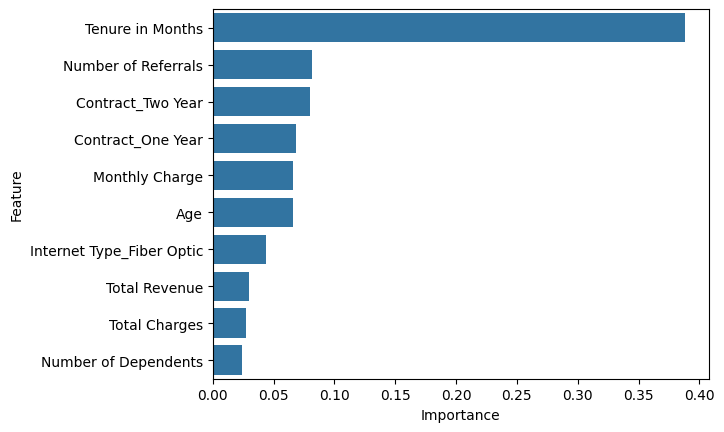

In [87]:
sns.barplot(
    data=rf_importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.show()

### Notes

* `Tenure in Months` was the most important feature used by the tuned Random Forest.

* `Number of Referrals`, contract type, `Monthly Charge`, and `Age` were also important for the model's predictions.

* The Random Forest used a wider range of features than the shallow Decision Tree.

* Feature importance shows which features the model relied on most, but it does not mean those features directly caused customers to churn.

## Gradient Boosting

### Baseline Gradient Boosting

In [88]:
gb = GradientBoostingClassifier(
    random_state=2026
)

gb.fit(X_train, y_train);

In [89]:
gb_train_predictions = gb.predict(X_train)
gb_test_predictions = gb.predict(X_test)

In [90]:
print(f"Train Accuracy: {accuracy_score(y_train, gb_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, gb_test_predictions)}")

Train Accuracy: 0.8920508442420793
Test Accuracy: 0.8884673748103187


In [91]:
print(confusion_matrix(y_train, gb_train_predictions))
print(confusion_matrix(y_test, gb_test_predictions))

[[3581  195]
 [ 374 1121]]
[[902  42]
 [105 269]]


### Notes

* The baseline Gradient Boosting model was about 89.2% accurate on the training data and 88.8% accurate on the test data.

* The similar training and test accuracy suggests that the model is not showing clear signs of overfitting.

* The model correctly predicted 269 customers who churned and missed 105 customers who churned.

### Tune the Gradient Boosting Model

In [92]:
parameters = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_features': [None, 'sqrt'],
    'subsample': [0.8, 0.9, 1.0],
    'max_depth': [2, 3, 5, 7],
    'min_samples_leaf': [2, 5, 10, 20]
}

In [93]:
gb_gridsearch = RandomizedSearchCV(
    GradientBoostingClassifier(
        random_state=2026
    ),
    parameters,
    n_iter=30,
    cv=5,
    scoring='f1',
    random_state=2026,
    n_jobs=-1
)

gb_gridsearch.fit(X_train, y_train);

In [94]:
gb_gridsearch.best_params_

{'subsample': 0.9,
 'n_estimators': 300,
 'min_samples_leaf': 2,
 'max_features': None,
 'max_depth': 7,
 'learning_rate': 0.01}

In [95]:
tuned_gb = gb_gridsearch.best_estimator_

In [96]:
tuned_gb_train_predictions = tuned_gb.predict(X_train)
tuned_gb_test_predictions = tuned_gb.predict(X_test)

In [97]:
print(f"Train Accuracy: {accuracy_score(y_train, tuned_gb_train_predictions)}")
print(f"Test Accuracy: {accuracy_score(y_test, tuned_gb_test_predictions)}")

Train Accuracy: 0.9225953329538987
Test Accuracy: 0.8846737481031867


In [98]:
print(confusion_matrix(y_train, tuned_gb_train_predictions))
print(confusion_matrix(y_test, tuned_gb_test_predictions))

[[3671  105]
 [ 303 1192]]
[[905  39]
 [113 261]]


### Notes

* RandomizedSearchCV selected the best Gradient Boosting settings based on the F1-score.

* The tuned model was about 92.3% accurate on the training data and 88.5% accurate on the test data.

* The tuned model performed slightly worse on the test data than the baseline Gradient Boosting model.

* The tuned model correctly predicted 261 customers who churned and missed 113 customers who churned.

* The larger gap between the training and test accuracy shows more signs of overfitting than the baseline model.

### Feature Importance

In [99]:
gb_importance_df = (
    pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': tuned_gb.feature_importances_
    })
    .sort_values(
        by='Importance',
        ascending=False
    )
)

gb_importance_df.head(10)

,Feature,Importance
3,Tenure in Months,0.382214
34,Contract_Two Year,0.086165
2,Number of Referrals,0.085622
33,Contract_One Year,0.074951
6,Monthly Charge,0.070005
0,Age,0.069125
1,Number of Dependents,0.040749
7,Total Charges,0.026614
11,Total Revenue,0.023159
10,Total Long Distance Charges,0.020170


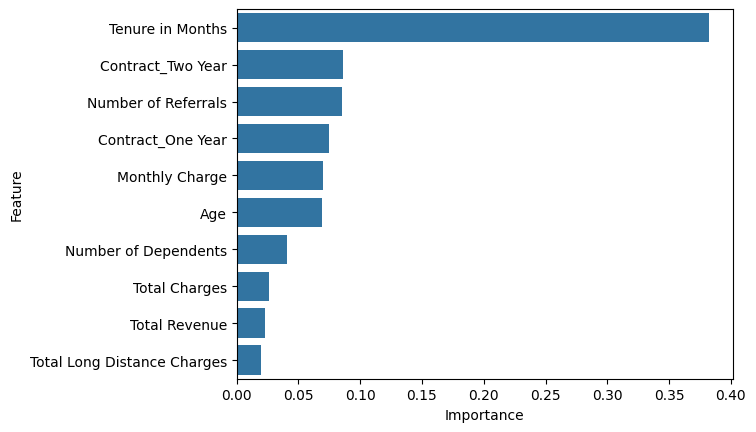

In [100]:
sns.barplot(
    data=gb_importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.show()

### Notes

* `Tenure in Months` was the most important feature used by the tuned Gradient Boosting model.

* `Contract_Two Year`, `Number of Referrals`, `Contract_One Year`, `Monthly Charge`, and `Age` were also important for the model's predictions.

* The model used a wider range of features, but tenure had much more importance than any other individual feature.

* Feature importance shows which features the model relied on most, but it does not mean those features directly caused customers to churn.

# 6. Compare Model Performance

The strongest version of each classification model is compared using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

In [101]:
tuned_knn_test_probabilities = tuned_knn.predict_proba(X_test)[:, 1]

logreg_test_probabilities = logreg.predict_proba(X_test_std)[:, 1]

tuned_dt_test_probabilities = tuned_dt.predict_proba(X_test)[:, 1]

tuned_rf_test_probabilities = tuned_rf.predict_proba(X_test)[:, 1]

gb_test_probabilities = gb.predict_proba(X_test)[:, 1]

In [102]:
model_results = pd.DataFrame({
    'Model': [
        'KNN',
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy_score(y_test, tuned_knn_test_predictions),
        accuracy_score(y_test, logreg_test_predictions),
        accuracy_score(y_test, tuned_dt_test_predictions),
        accuracy_score(y_test, tuned_rf_test_predictions),
        accuracy_score(y_test, gb_test_predictions)
    ],
    'Precision': [
        precision_score(y_test, tuned_knn_test_predictions),
        precision_score(y_test, logreg_test_predictions),
        precision_score(y_test, tuned_dt_test_predictions),
        precision_score(y_test, tuned_rf_test_predictions),
        precision_score(y_test, gb_test_predictions)
    ],
    'Recall': [
        recall_score(y_test, tuned_knn_test_predictions),
        recall_score(y_test, logreg_test_predictions),
        recall_score(y_test, tuned_dt_test_predictions),
        recall_score(y_test, tuned_rf_test_predictions),
        recall_score(y_test, gb_test_predictions)
    ],
    'F1 Score': [
        f1_score(y_test, tuned_knn_test_predictions),
        f1_score(y_test, logreg_test_predictions),
        f1_score(y_test, tuned_dt_test_predictions),
        f1_score(y_test, tuned_rf_test_predictions),
        f1_score(y_test, gb_test_predictions)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, tuned_knn_test_probabilities),
        roc_auc_score(y_test, logreg_test_probabilities),
        roc_auc_score(y_test, tuned_dt_test_probabilities),
        roc_auc_score(y_test, tuned_rf_test_probabilities),
        roc_auc_score(y_test, gb_test_probabilities)
    ]
})

model_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.810,0.653,0.709,0.679,0.876
1,Logistic Regression,0.856,0.751,0.735,0.743,0.917
2,Decision Tree,0.867,0.818,0.684,0.745,0.922
3,Random Forest,0.885,0.861,0.711,0.779,0.938
4,Gradient Boosting,0.888,0.865,0.719,0.785,0.942


### Notes

* Gradient Boosting had the highest Accuracy, Precision, F1-score, and ROC-AUC out of the models tested.

* Logistic Regression had the highest Recall, meaning it was able to identify the most customers who actually churned.

* Random Forest also had a strong performance across the evaluation metrics.

* KNN had the lowest overall performance compared to the other models.

## ROC Curves

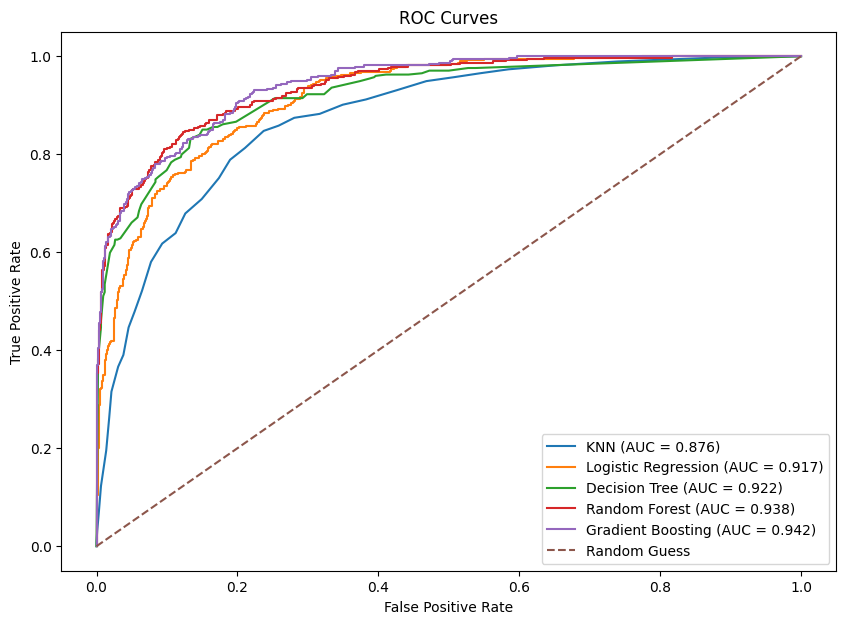

In [103]:
models_probabilities = {
    'KNN': tuned_knn_test_probabilities,
    'Logistic Regression': logreg_test_probabilities,
    'Decision Tree': tuned_dt_test_probabilities,
    'Random Forest': tuned_rf_test_probabilities,
    'Gradient Boosting': gb_test_probabilities
}

plt.figure(figsize=(10, 7))

for model_name, probabilities in models_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc_score:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Guess'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()

### Notes

* Gradient Boosting had the highest ROC-AUC at 0.942, followed closely by Random Forest at 0.938.

* Decision Tree and Logistic Regression also did a good job separating customers who stayed from customers who churned.

* KNN had the lowest ROC-AUC out of the models tested.

* All five models performed better than random guessing.

## Precision-Recall Curves

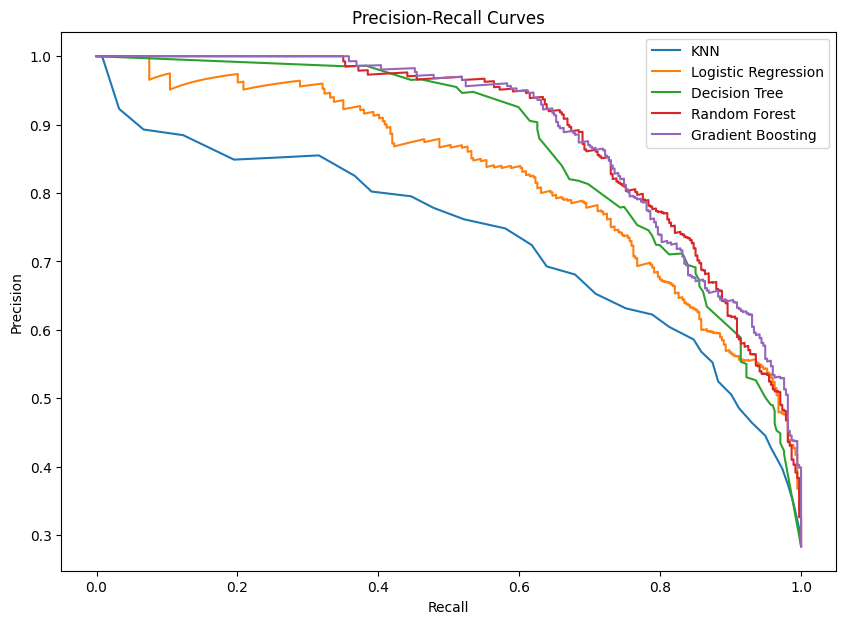

In [104]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in models_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=model_name
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend()
plt.show()

### Notes

* Gradient Boosting and Random Forest had two of the strongest Precision-Recall curves overall.

* Decision Tree also performed well, while Logistic Regression had lower Precision as Recall increased.

* KNN had the weakest Precision-Recall performance compared to the other models.

## Final Model Selection

In [105]:
final_model = gb

final_test_predictions = gb_test_predictions
final_test_probabilities = gb_test_probabilities

### Notes

* Gradient Boosting had the highest Accuracy at 88.8%, Precision at 86.5%, F1-score at 78.5%, and ROC-AUC at 94.2%.

* Logistic Regression had the highest Recall at 73.5%, while Gradient Boosting had a Recall of 71.9%.

* Although Logistic Regression identified slightly more customers who churned, Gradient Boosting provided a stronger overall balance between Precision and Recall.

* Random Forest also performed very well, but Gradient Boosting had slightly better results across all five evaluation metrics.

* Based on the overall results, Gradient Boosting was selected as the final model for predicting customer churn.

## Adjust the Classification Threshold

Gradient Boosting uses a default classification threshold of 0.50. Lower thresholds are tested to see if the model can identify more customers who churn without lowering Precision too much.

In [106]:
gb_cv_probabilities = cross_val_predict(
    GradientBoostingClassifier(
        random_state=2026
    ),
    X_train,
    y_train,
    cv=5,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [107]:
thresholds = [0.50, 0.45, 0.40, 0.35]

In [108]:
threshold_results = []

for threshold in thresholds:
    predictions = (
        gb_cv_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions
    ).ravel()

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(
            y_train,
            predictions
        ),
        'Precision': precision_score(
            y_train,
            predictions
        ),
        'Recall': recall_score(
            y_train,
            predictions
        ),
        'F1 Score': f1_score(
            y_train,
            predictions
        ),
        'Churners Found': tp,
        'Churners Missed': fn
    })

In [109]:
threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df.round(3)

,Threshold,Accuracy,Precision,Recall,F1 Score,Churners Found,Churners Missed
0,0.50,0.873,0.817,0.709,0.759,1060,435
1,0.45,0.871,0.793,0.739,0.765,1105,390
2,0.40,0.865,0.759,0.769,0.764,1149,346
3,0.35,0.860,0.732,0.799,0.764,1195,300


### Notes

* Lowering the threshold increased Recall, meaning the model was able to identify more customers who churned.

* The threshold of 0.45 had the highest F1-score at 76.5%.

* At 0.45, the model identified 45 more customers who churned and missed 45 fewer compared to the default threshold of 0.50.

* Precision decreased from 81.7% to 79.3%, while Accuracy stayed almost the same.

* Based on these results, 0.45 was selected as the adjusted classification threshold.

In [110]:
selected_threshold = 0.45

In [111]:
adjusted_test_predictions = (
    final_test_probabilities >= selected_threshold
).astype(int)

In [112]:
threshold_test_results = pd.DataFrame({
    'Threshold': [0.50, selected_threshold],
    'Accuracy': [
        accuracy_score(y_test, final_test_predictions),
        accuracy_score(y_test, adjusted_test_predictions)
    ],
    'Precision': [
        precision_score(y_test, final_test_predictions),
        precision_score(y_test, adjusted_test_predictions)
    ],
    'Recall': [
        recall_score(y_test, final_test_predictions),
        recall_score(y_test, adjusted_test_predictions)
    ],
    'F1 Score': [
        f1_score(y_test, final_test_predictions),
        f1_score(y_test, adjusted_test_predictions)
    ]
})

threshold_test_results.round(3)

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.50,0.888,0.865,0.719,0.785
1,0.45,0.882,0.825,0.743,0.782


In [113]:
confusion_matrix(
    y_test,
    adjusted_test_predictions
)

array([[885,  59],
       [ 96, 278]])

### Test Results

* Lowering the threshold from 0.50 to 0.45 increased Recall from 71.9% to 74.3%.

* At 0.45, the model identified 9 more customers who churned and missed 9 fewer customers.

* Precision decreased from 86.5% to 82.5%, while Accuracy decreased slightly from 88.8% to 88.2%.
The F1-score also decreased slightly from 78.5% to 78.2%.

* Based on the test results, the final model will keep the default threshold of 0.50. The 0.45 threshold could still be used if the company wants to prioritize identifying more customers who may churn.

# 7. Business Insights and Recommendations

## Key Business Insights

* Customers with shorter tenure were more likely to churn.

* Customers with month-to-month contracts had a much higher churn rate than customers with one-year or two-year contracts.

* Customers without Online Security or Premium Tech Support had higher churn rates.
Fiber Optic customers had a higher churn rate compared to customers using other internet types.

* Customers who churned generally had fewer referrals than customers who stayed.

* Competitor-related reasons were the most common reported churn category, with better competitor devices and offers among the most common individual reasons.

* Gradient Boosting was selected as the final model and achieved 88.8% Accuracy, 86.5% Precision, 71.9% Recall, a 78.5% F1-score, and a 94.2% ROC-AUC.

* Lowering the classification threshold from 0.50 to 0.45 helped the model identify more customers who churned, but the default threshold of 0.50 provided a slightly better overall balance across the evaluation metrics.

## Recommendations

* Focus retention efforts on newer customers, especially during their first few months with the company.

* Pay close attention to customers with month-to-month contracts since they had a much higher churn rate. The company could encourage these customers to switch to longer contracts by offering discounts or other incentives.

* Consider promoting Online Security and Premium Tech Support to customers who do not currently use these services.

* Review the Fiber Optic customer experience to better understand why these customers are leaving at a higher rate.

* Review competitor offers and device options and look for ways to improve the company's own offers for customers who may be considering leaving.

* Use the Gradient Boosting model to identify customers who may be likely to churn so the company can reach out to them before they leave.

* If the company wants to find more customers who may churn, it could use the lower 0.45 threshold. However, this would also incorrectly flag more customers who would have stayed.

## Conclusion

The analysis brought several patterns to light that can help the company better understand customer churn. Customers with shorter tenure and month-to-month contracts were more likely to churn. Higher churn rates were also seen among customers without Online Security or Premium Tech Support and among Fiber Optic customers.

Gradient Boosting provided the strongest overall model performance and can help the company identify customers who may be at risk of churning. These predictions, along with the patterns found during the analysis, can help the company focus its retention efforts on customers who may need the most attention.

**Note:** These results show patterns in the customer data, but they do not prove that any individual feature directly causes a customer to churn.